In [1]:
# === LOAD: locate repo and load `sessions` with all_data_df ===
import sys, pickle
from pathlib import Path
import pandas as pd

# Try to discover the repo root from the current notebook location
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    # fallback to your known absolute path
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

# Make package importable (optional, but matches your pattern)
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

# Optional sanity check for the package
try:
    import importlib; importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

# Default PKL path from your earlier snippet
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_sylls.pkl"

# Fallback: search for a suitable PKL if the default is missing
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    # pick the most recent
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

with PKL.open("rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions from {PKL}")

# Keep only sessions that actually have non-empty all_data_df
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

# Quick peek
if sessions:
    s0 = sessions[0]
    sid  = getattr(s0, "session_id", "<no id>")
    geno = (getattr(s0, "metadata", {}) or {}).get("genotype", "UNK")
    print(f"Example session: {sid} | genotype={geno}")
    display(s0.all_data_df.head())
else:
    raise RuntimeError("No usable sessions found; check your pickle or preprocessing.")


/tmp/ipykernel_596252/2962148787.py:42: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  sessions = pickle.load(f)


Loaded 19 sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls.pkl
Usable sessions with all_data_df: 19
Example session: 2024-12-13T12_20_06_bottom_left | genotype=WT


,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset,...,signal_0_zscore_datta,signal_1_dff,signal_1_zscore,signal_1_zscore_datta,signal_2_dff,signal_2_zscore,signal_2_zscore_datta,signal_3_dff,signal_3_zscore,signal_3_zscore_datta
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,69517,WT,True,...,0.284346,-0.456758,-0.635931,-0.340642,-0.342478,-0.795487,-1.066838,-0.565258,-0.636459,-0.953344
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,69518,WT,False,...,0.458511,-0.457280,-0.642150,-0.387259,-0.341230,-0.789986,-1.007153,-0.565216,-0.636034,-0.862807
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,69519,WT,False,...,0.632677,-0.457802,-0.648369,-0.433876,-0.339982,-0.784485,-0.947469,-0.565174,-0.635609,-0.772271
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,69520,WT,False,...,0.806842,-0.458323,-0.654588,-0.480492,-0.338734,-0.778983,-0.887785,-0.565133,-0.635184,-0.681734
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,69521,WT,False,...,1.072744,-0.457493,-0.644689,-0.433324,-0.338548,-0.778165,-0.890066,-0.563833,-0.621913,-0.537591


In [2]:
import re

print("--- RE-BAKING REGION NAMES (e.g., 'DMS' -> 'L-DMS') ---")

patched_count = 0

for s in sessions:
    sig_meta = s.metadata.get("signal_meta", {})
    if not sig_meta: 
        continue
        
    for key, info in sig_meta.items():
        # 1. Get current values
        raw_reg = str(info.get("brain_reg", "UNK"))
        hemi = str(info.get("hemisphere", "UNK")).strip().upper()
        
        # 2. Clean the base name first (remove any existing prefixes to avoid L-L-DMS)
        # "L-DMS" -> "DMS", "DMS" -> "DMS"
        base_reg = re.sub(r"^[LRlr][\s\-_]+", "", raw_reg).strip().upper()
        
        # 3. Skip if invalid
        if base_reg in ["UNK", "", "NONE", "NAN"]:
            info["brain_reg"] = "UNK"
            continue

        # 4. Construct the "Cheater" Name
        # If we have a valid hemisphere, prepend it
        if hemi in ["L", "R", "LEFT", "RIGHT"]:
            # Normalize to L/R
            short_hemi = "L" if hemi.startswith("L") else "R"
            
            # THE CHANGE: Bake it into the string
            new_reg_name = f"{short_hemi}-{base_reg}"
            
            # Save it back
            info["brain_reg"] = new_reg_name
            # Ensure hemisphere key stays accurate too
            info["hemisphere"] = short_hemi 
        else:
            # If no hemisphere known, keep base name but warn?
            # Or leave as is.
            info["brain_reg"] = base_reg
            
    patched_count += 1

print(f"✅ Re-baked region names for {patched_count} sessions.")

# --- VERIFICATION ---
print("\n[Check] Session 0 Signal Metadata:")
for k, v in sessions[0].metadata['signal_meta'].items():
    print(f"  {k}: Region='{v['brain_reg']}'") 
    # Expect: 'L-DMS', 'R-VS', etc.

--- RE-BAKING REGION NAMES (e.g., 'DMS' -> 'L-DMS') ---
✅ Re-baked region names for 19 sessions.

[Check] Session 0 Signal Metadata:
  signal_0: Region='L-DMS'
  signal_1: Region='L-DMS'
  signal_2: Region='R-VS'
  signal_3: Region='R-VS'


In [3]:
for s in sessions:
    print(s.metadata['signal_meta'])

{'signal_0': {'orig_fiber': 'G4', 'orig_letter': 'G', 'fiber_num': '4', 'hemisphere': 'L', 'brain_reg': 'L-DMS'}, 'signal_1': {'orig_fiber': 'R5', 'orig_letter': 'R', 'fiber_num': '5', 'hemisphere': 'L', 'brain_reg': 'L-DMS'}, 'signal_2': {'orig_fiber': 'G6', 'orig_letter': 'G', 'fiber_num': '6', 'hemisphere': 'R', 'brain_reg': 'R-VS'}, 'signal_3': {'orig_fiber': 'R7', 'orig_letter': 'R', 'fiber_num': '7', 'hemisphere': 'R', 'brain_reg': 'R-VS'}}
{'signal_0': {'orig_fiber': 'G8', 'orig_letter': 'G', 'fiber_num': '8', 'hemisphere': 'L', 'brain_reg': 'L-DMS'}, 'signal_1': {'orig_fiber': 'R9', 'orig_letter': 'R', 'fiber_num': '9', 'hemisphere': 'L', 'brain_reg': 'L-DMS'}, 'signal_2': {'orig_fiber': 'G10', 'orig_letter': 'G', 'fiber_num': '10', 'hemisphere': 'R', 'brain_reg': 'R-VS'}, 'signal_3': {'orig_fiber': 'R11', 'orig_letter': 'R', 'fiber_num': '11', 'hemisphere': 'R', 'brain_reg': 'R-VS'}}
{'signal_0': {'orig_fiber': 'G0', 'orig_letter': 'G', 'fiber_num': '0', 'hemisphere': 'L', 'br

In [4]:
lst = []

for s in sessions:
    lst.append(s.metadata['animal_id'])

len(set(lst))


18

# 📚 Data Dictionary: Kinematics Long-Form

This dataframe (`kinematics_long_df`) aggregates behavioral statistics at the **Session × Syllable** level.

### 🔑 Identifiers
| Column | Description |
| :--- | :--- |
| **`session_id`** | Unique session identifier (Timestamp + Chamber). |
| **`animal_id`** | Subject identifier. |
| **`genotype`** | Subject genotype (e.g., WT, KI). |
| **`syllable`** | The MoSeq syllable ID (integer). |

### ⏱️ Usage & Timing
| Column | Description |
| :--- | :--- |
| **`total_occurrences`** | Count of how many times this syllable was initiated. |
| **`total_duration_s`** | Total time spent performing this syllable. |
| **`duration_avg`** | Mean duration of the syllable (Sensitive to outliers). |
| **`duration_median`** | **Robust** median duration (Best for "typical" length). |
| **`duration_cv`** | **Coefficient of Variation** (`std / mean`). <br>• **Low**: Highly stereotyped/robotic behavior.<br>• **High**: Variable/exploratory execution. |

### 🚀 Kinematics: Vigor & Velocity
*Note: "p95" metrics filter out single-frame tracking glitches.*

| Column | Description |
| :--- | :--- |
| **`velocity_avg`** | The average speed (px/s) across all frames of this syllable. |
| **`velocity_peak_avg`** | The mean of the **absolute max** speeds. (High sensitivity to tracking noise). |
| **`velocity_p95_avg`** | The mean of the **95th percentile** speeds. Filters out 1-2 frame camera jumps. |
| **`velocity_p95_median`** | **🛡️ Fully Robust Vigor**: The median of the 95th percentile speeds. <br>Ignores both tracking glitches AND outlier trials. **Use this for correlations.** |

### ⚡ Kinematics: Motor Drive
| Column | Description |
| :--- | :--- |
| **`accel_avg`** | Average acceleration. Represents general motor drive. |
| **`accel_p95_median`** | **Robust Explosiveness**: How fast the animal accelerates during the most vigorous part of the movement, filtering outliers. |

### 📐 Spatial & Geometry
| Column | Description |
| :--- | :--- |
| **`avg_angular_velocity`** | Turning speed (rad/s). High = Spinning/Orienting. |
| **`dist_center_avg`** | Distance from arena center. High = Thigmotaxis (Anxiety?). |
| **`tortuosity_avg`** | Path straightness (1.0 = Straight, >1.0 = Meandering). |

In [5]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

# ==========================================
# 1. CONFIGURATION
# ==========================================
RAW_COLS = ['velocity_px_s', 'angular_velocity', 'centroid_x', 'centroid_y']

# ==========================================
# 2. AGGREGATION LOOP
# ==========================================
rows = []

print(f"Computing Advanced Kinematics for {len(sessions)} sessions...")

for session in sessions:
    # --- A. Metadata & Validation ---
    meta = session.metadata if hasattr(session, "metadata") else {}
    sid = session.session_id
    geno = meta.get("genotype", "UNK")
    
    df = session.all_data_df
    if df is None or df.empty: continue
        
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
        
    # --- C. Pre-Calculate Frame-Level Features ---
    df["acceleration"] = np.gradient(df["velocity_px_s"], 1/fs)
    
    cx, cy = df["centroid_x"].mean(), df["centroid_y"].mean()
    df["dist_from_center"] = np.sqrt((df["centroid_x"] - cx)**2 + (df["centroid_y"] - cy)**2)
    
    # --- D. Define Instances (Runs) ---
    df["instance_id"] = (df["syllable"] != df["syllable"].shift(1)).cumsum()
    
    # --- E. STEP 1: Instance-Level Aggregation ---
    instance_stats = df.groupby(["syllable", "instance_id"]).agg(
        # Timing
        duration_frames=("syllable", "count"),
        
        # Vigor / Intensity (Standard)
        mean_vel=("velocity_px_s", "mean"),
        peak_vel=("velocity_px_s", "max"),      
        
        # Vigor / Intensity (Robust Frame-Level)
        # 95th percentile filters out 1-2 frame tracking errors
        p95_vel=("velocity_px_s", lambda x: np.percentile(x, 95)),

        # Acceleration
        mean_accel=("acceleration", "mean"),
        peak_accel=("acceleration", "max"),
        p95_accel=("acceleration", lambda x: np.percentile(x, 95)),
        
        # Geometry/Spatial
        mean_ang_vel=("angular_velocity", "mean"),
        mean_dist_center=("dist_from_center", "mean"),
        
        # Path Integration
        start_x=("centroid_x", "first"),
        end_x=("centroid_x", "last"),
        start_y=("centroid_y", "first"),
        end_y=("centroid_y", "last"),
        path_length=("velocity_px_s", "sum")
    ).reset_index()
    
    # Refine Metrics
    instance_stats["duration_s"] = instance_stats["duration_frames"] / fs
    
    dx = instance_stats["end_x"] - instance_stats["start_x"]
    dy = instance_stats["end_y"] - instance_stats["start_y"]
    displacement = np.sqrt(dx**2 + dy**2)
    
    instance_stats["total_dist"] = instance_stats["path_length"] * (1/fs)
    instance_stats["tortuosity"] = instance_stats["total_dist"] / (displacement + 1e-6)

    # --- F. STEP 2: Session-Level Aggregation ---
    summary = instance_stats.groupby("syllable").agg(
        count=("instance_id", "count"),
        total_time_s=("duration_s", "sum"),
        
        # --- DURATION ---
        duration_avg=("duration_s", "mean"),
        duration_median=("duration_s", "median"), # Robust center
        duration_std=("duration_s", "std"),
        
        # --- VELOCITY (MEAN) ---
        velocity_avg=("mean_vel", "mean"),
        
        # --- VELOCITY (PEAKS - VIGOR) ---
        # 1. Standard (Sensitive to outliers)
        velocity_peak_avg=("peak_vel", "mean"), 
        
        # 2. Session Robust (Ignores outlier trials)
        velocity_peak_median=("peak_vel", "median"),
        
        # 3. Tracking Robust (Ignores single-frame glitches)
        velocity_p95_avg=("p95_vel", "mean"),
        
        # 4. Fully Robust (The "Gold Standard" for analysis)
        velocity_p95_median=("p95_vel", "median"),
        
        # --- ACCELERATION ---
        accel_avg=("mean_accel", "mean"),
        accel_peak_avg=("peak_accel", "mean"),
        accel_p95_median=("p95_accel", "median"), 
        
        # --- GEOMETRY ---
        avg_angular_velocity=("mean_ang_vel", "mean"),
        tortuosity_avg=("tortuosity", "mean"),
        dist_center_avg=("mean_dist_center", "mean")
    ).reset_index()
    
    summary["duration_cv"] = summary["duration_std"] / (summary["duration_avg"] + 1e-9)
    
    # Add Meta
    summary["session_id"] = sid
    summary["genotype"] = geno
    summary["animal_id"] = meta.get("animal_id", "UNK")
    
    rows.append(summary)

# ==========================================
# 3. FINALIZE
# ==========================================
if rows:
    long_df = pd.concat(rows, ignore_index=True)
    
    # Reorder nicely
    meta_cols = ["session_id", "animal_id", "genotype", "syllable"]
    stat_cols = [c for c in long_df.columns if c not in meta_cols]
    long_df = long_df[meta_cols + stat_cols]
    
    print(f"Generated Rich Kinematics DF: {long_df.shape}")
    display(long_df.head())
    
    # Quick Sanity Check
    print("\n--- Genotype Comparison (Mean Duration & Vigor) ---")
    # Added velocity_p95_median to check robustness
    display(long_df.groupby("genotype")[["duration_avg", "duration_cv", "velocity_avg", "velocity_p95_median"]].mean())
else:
    print("No data found.")

Computing Advanced Kinematics for 19 sessions...
Generated Rich Kinematics DF: (1466, 21)


,session_id,animal_id,genotype,syllable,count,total_time_s,duration_avg,duration_median,duration_std,velocity_avg,...,velocity_peak_median,velocity_p95_avg,velocity_p95_median,accel_avg,accel_peak_avg,accel_p95_median,avg_angular_velocity,tortuosity_avg,dist_center_avg,duration_cv
0,2024-12-13T12_20_06_bottom_left,740,WT,0,82,25.154448,0.306762,0.224928,0.315028,36.341182,...,61.002838,62.127019,51.190408,42.774515,1601.467590,1215.834442,-0.584271,14974.685228,147.634620,1.026947
1,2024-12-13T12_20_06_bottom_left,740,WT,2,44,143.691504,3.265716,2.080584,3.216287,26.053615,...,68.027879,51.776537,47.012922,-9.754136,1989.839395,1136.433945,0.030948,18.654081,151.631274,0.984864
2,2024-12-13T12_20_06_bottom_left,740,WT,3,26,10.059280,0.386895,0.199936,0.502762,28.410045,...,55.835693,49.054443,43.942842,-15.530643,1324.533991,1084.896558,0.198900,15050.541630,143.396648,1.299477
3,2024-12-13T12_20_06_bottom_left,740,WT,4,132,20.268512,0.153549,0.124960,0.121286,35.723970,...,59.711300,55.902675,54.031823,-33.898247,1241.980506,1180.280224,0.205292,28878.689084,150.455958,0.789885
4,2024-12-13T12_20_06_bottom_left,740,WT,5,13,1.374560,0.105735,0.074976,0.117180,147.339860,...,160.938799,198.890774,156.012794,-162.058811,1502.619687,528.791557,-1.625280,0.871385,148.041023,1.108240



--- Genotype Comparison (Mean Duration & Vigor) ---


,duration_avg,duration_cv,velocity_avg,velocity_p95_median
genotype,,,,
KI,0.742847,0.832763,36.896439,59.671996
UNK,0.939278,0.864995,35.195909,55.948181
WT,0.905433,0.897753,33.030868,53.129944


# General syllable tests

### Does an onset peak/dip more than random timepoints?

1. Scanning 19 sessions (Splitting L/R)...


/tmp/ipykernel_596252/965869936.py:128: RuntimeWarning: Mean of empty slice
  mu_actual = np.nanmean(stack, axis=0)
/tmp/ipykernel_596252/965869936.py:137: RuntimeWarning: Mean of empty slice
  shuff_stack_means.append(np.nanmean(s_stack, axis=0))
/tmp/ipykernel_596252/965869936.py:137: RuntimeWarning: Mean of empty slice
  shuff_stack_means.append(np.nanmean(s_stack, axis=0))


Data aggregated. Regions found: ['L-DLS', 'L-DMS', 'L-VS', 'R-DLS', 'R-DMS', 'R-VS']
2. Running 1000 bootstraps (Actual vs Null)...


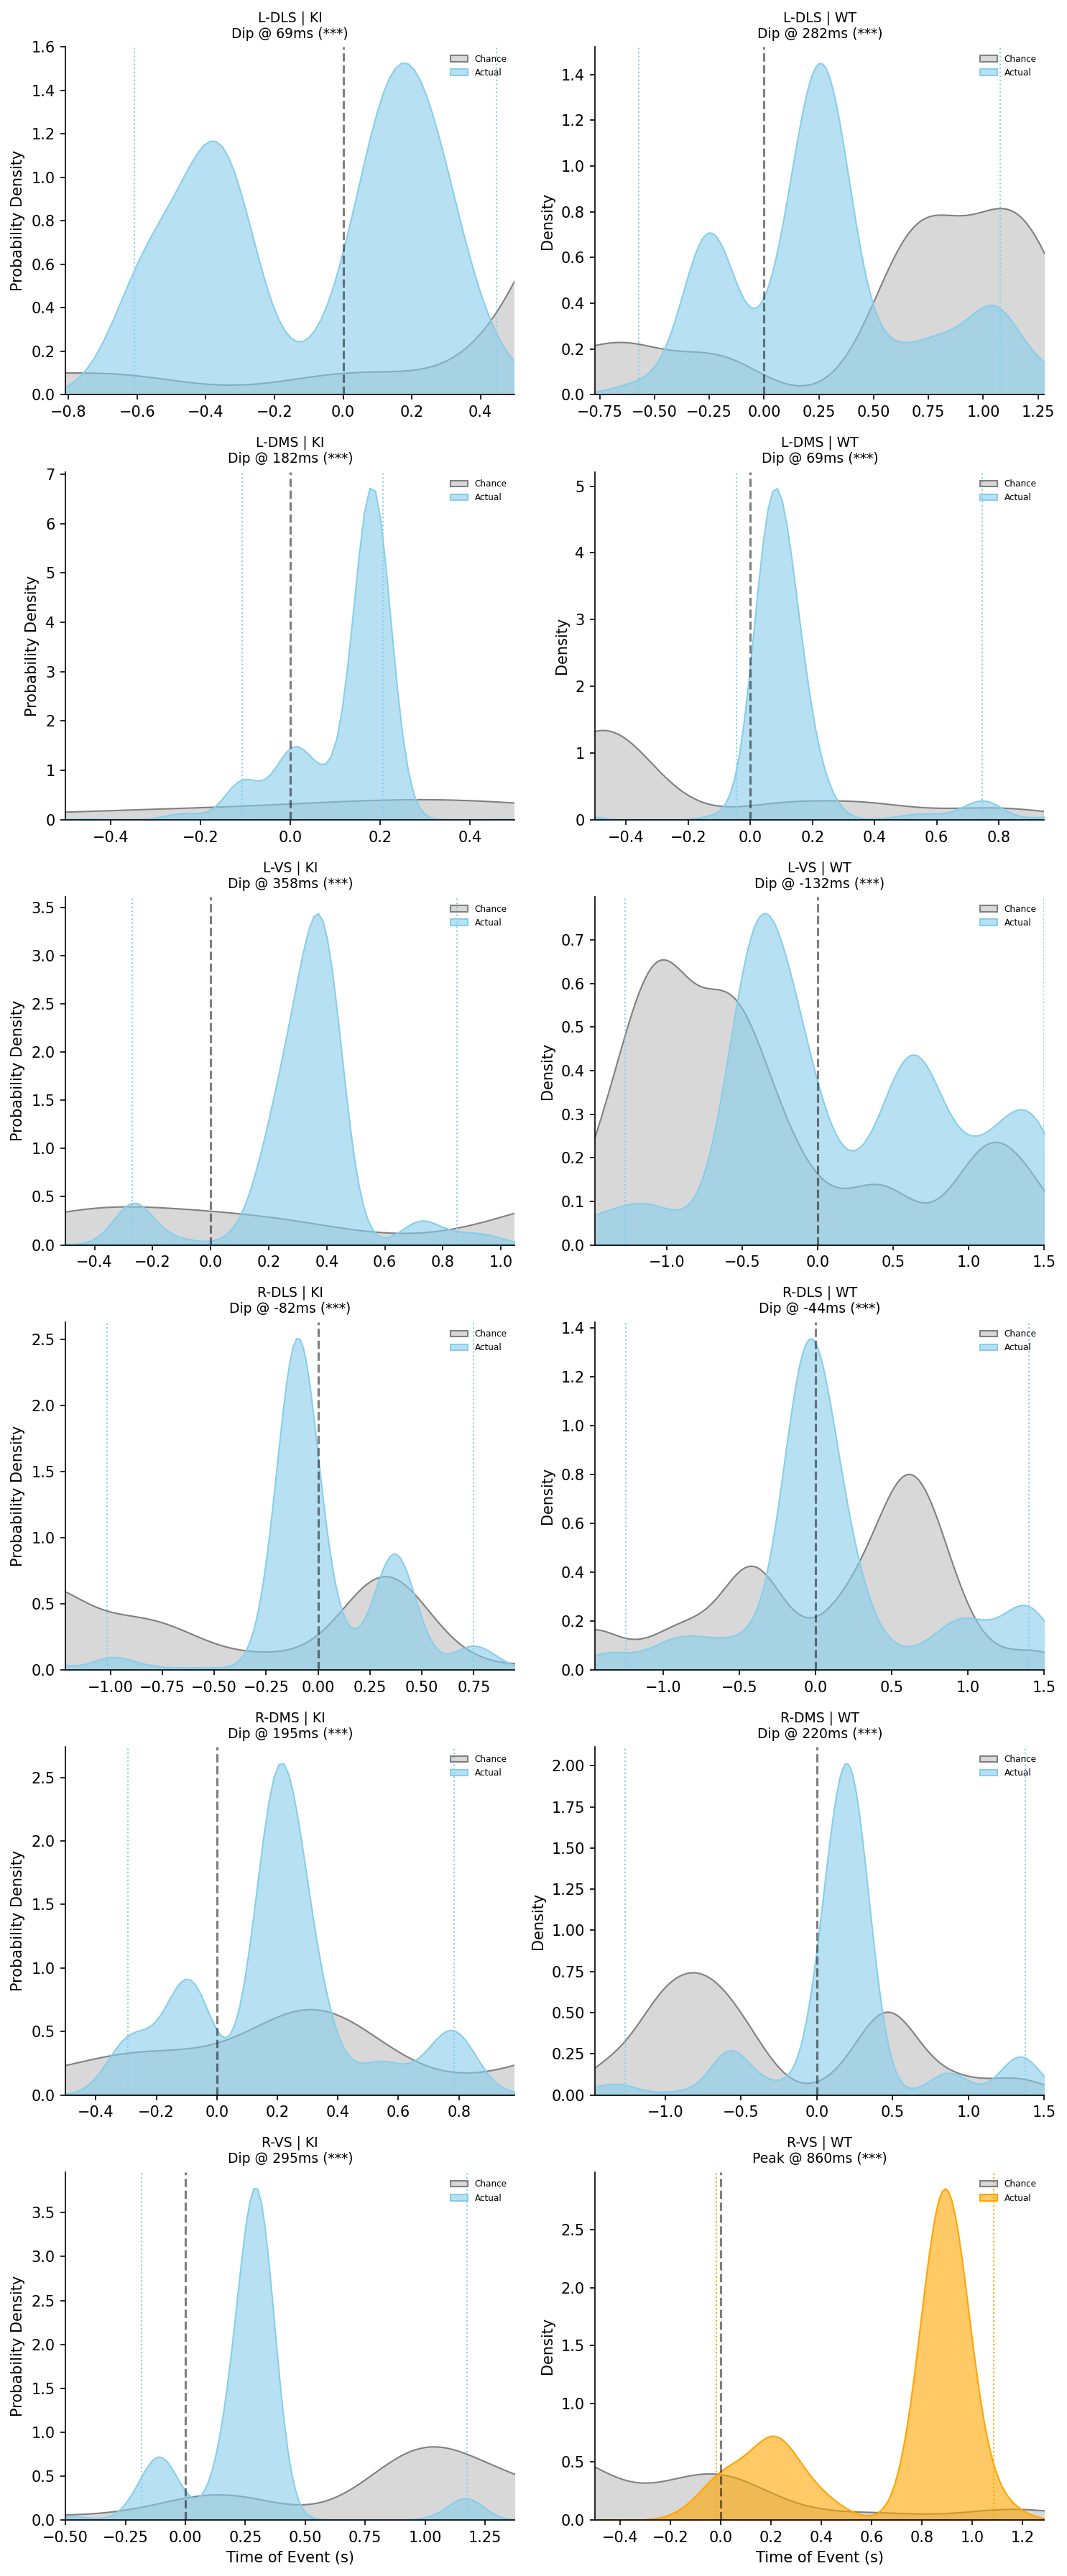


=== HYPOTHESIS TEST: Does Onset Predict Peak Timing? (KS-Test) ===
Condition       | Type | Peak Time (95% CI)        | Significance
---------------------------------------------------------------------------
L-DLS|KI        | Dip  | -609ms to 446ms           | p=3.8e-280 (SIG)
L-DLS|WT        | Dip  | -571ms to 1079ms          | p=7.6e-130 (SIG)
L-DMS|KI        | Dip  | -107ms to 207ms           | p=7.0e-108 (SIG)
L-DMS|WT        | Dip  | -45ms to 747ms            | p=1.4e-250 (SIG)
L-VS|KI         | Dip  | -270ms to 847ms           | p=1.1e-104 (SIG)
L-VS|WT         | Dip  | -1274ms to 1500ms         | p=8.5e-128 (SIG)
R-DLS|KI        | Dip  | -1016ms to 747ms          | p=1.8e-114 (SIG)
R-DLS|WT        | Dip  | -1249ms to 1400ms         | p=2.7e-48 (SIG)
R-DMS|KI        | Dip  | -295ms to 785ms           | p=2.3e-64 (SIG)
R-DMS|WT        | Dip  | -1262ms to 1374ms         | p=2.9e-126 (SIG)
R-VS|KI         | Dip  | -182ms to 1174ms          | p=2.4e-168 (SIG)
R-VS|WT         | Peak

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# --- TIME & SIGNAL ---
WINDOW_SEC = 1.5           # +/- 1.5s around onset
SHUFFLE_JITTER_SEC = 2.0   # +/- 2.0s jitter
N_SHUFFLES = 20            # Shuffles per trial for Null construction

# --- STATISTICS ---
N_BOOTSTRAPS = 1000        # Resamples for CI/KS test
CONFIDENCE_LEVEL = 0.95    
MIN_TRIALS_FOR_STATS = 100 # Drop rare syllables

# --- DATA SELECTION ---
TARGET_ORIG_LETTER = "G"   
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# ==========================================
# 2. HELPER: BESSEL FILTER
# ==========================================
def apply_bessel_filter(series, fs):
    nyquist = fs / 2.0
    if nyquist <= 1.0: return series 
    sos = signal.bessel(1, 1.0 / nyquist, btype="high", output="sos")
    
    valid_mask = ~np.isnan(series)
    result = np.full_like(series, np.nan)
    if np.sum(valid_mask) > 10:
        result[valid_mask] = signal.sosfiltfilt(sos, series[valid_mask])
    return result

# ==========================================
# 3. AGGREGATION (With Hemisphere Split)
# ==========================================
# Structure: buckets[geno][region_hemi][syll] -> list of data
data_buckets = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))

# CONFIG FOR THIS RUN
TARGET_ORIG_LETTER = "G"  # Only Green
IGNORE_HEMIS = {"UNK", None, "nan"}

print(f"1. Scanning {len(sessions)} sessions (Splitting L/R)...")

for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    
    window_frames = int(WINDOW_SEC * fs)
    jitter_frames = int(SHUFFLE_JITTER_SEC * fs)
    
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    
    onset_indices = np.flatnonzero(onsets)
    if len(onset_indices) == 0: continue
    syllable_array = df["syllable"].to_numpy()
    
    # --- SIGNAL EXTRACTION LOOP ---
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # 1. Filter for GREEN only
        color = str(info.get("orig_letter", "")).upper()
        # Fallback if missing
        if not color and "fiber_num" in info:
             color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
        
        if color != TARGET_ORIG_LETTER: continue

        # 2. Get Anatomy (ALREADY PATCHED)
        # Because we ran the global patch, 'brain_reg' is already "L-DLS", "R-VS", etc.
        region_name = str(info.get("brain_reg", "UNK")).strip()
        
        if region_name in IGNORE_REGIONS or region_name == "UNK": continue
        
        # 3. Get Data
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        else: continue

        raw_sig = df[col_name].to_numpy()
        filtered_sig = apply_bessel_filter(raw_sig, fs)
        max_idx = len(filtered_sig) - 1
        
        # 4. Group by Syllable
        syll_map = defaultdict(list)
        for idx in onset_indices:
            syll_map[syllable_array[idx]].append(idx)
            
        for syll, indices in syll_map.items():
            indices = np.array(indices)
            starts = indices - window_frames
            ends = indices + window_frames
            valid = (starts >= 0) & (ends <= max_idx)
            if not np.any(valid): continue
            
            n_trials = np.sum(valid)
            
            # Actual
            stack = np.array([filtered_sig[s:e] for s, e in zip(starts[valid], ends[valid])])
            if np.isnan(stack).all(): continue
            mu_actual = np.nanmean(stack, axis=0)
            
            # Shuffle
            shifts = np.random.randint(-jitter_frames, jitter_frames, size=(N_SHUFFLES, n_trials))
            shuff_stack_means = []
            for i in range(N_SHUFFLES):
                s_starts = np.clip(starts[valid] + shifts[i], 0, max_idx - 2*window_frames)
                s_ends = s_starts + 2*window_frames
                s_stack = np.array([filtered_sig[s:e] for s, e in zip(s_starts, s_ends)])
                shuff_stack_means.append(np.nanmean(s_stack, axis=0))
            mu_shuffle = np.mean(shuff_stack_means, axis=0)
            
            # Use the region name DIRECTLY
            data_buckets[geno][region_name][syll].append((n_trials, mu_actual, mu_shuffle))

print(f"Data aggregated. Regions found: {sorted({r for g in data_buckets for r in data_buckets[g]})}")

# ==========================================
# 4. STATISTICAL ANALYSIS & PLOTTING
# ==========================================
print(f"2. Running {N_BOOTSTRAPS} bootstraps (Actual vs Null)...")

results = {} 

unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

fig, axes = plt.subplots(
    nrows=len(unique_regions), ncols=len(unique_genos), 
    figsize=(5 * len(unique_genos), 4 * len(unique_regions)),
    dpi=150, sharex=False, sharey=False # False to allow dynamic zoom
)

if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

for r_idx, region in enumerate(unique_regions):
    for c_idx, geno in enumerate(unique_genos):
        ax = axes[r_idx, c_idx]
        syll_data = data_buckets[geno].get(region, {})
        
        if not syll_data:
            ax.text(0.5, 0.5, "No Data", ha='center', va='center'); continue

        # --- A. POOL TRACES ---
        pool_actual = []
        pool_shuffle = [] 
        
        for syll, session_list in syll_data.items():
            total_trials = sum(item[0] for item in session_list)
            if total_trials < MIN_TRIALS_FOR_STATS: continue
            
            # Weighted Means to reconstruct Global Avg for this Syllable
            weighted_actual = np.zeros_like(session_list[0][1])
            weighted_shuffle = np.zeros_like(session_list[0][2])
            
            for n, act, shuff in session_list:
                weighted_actual += act * n
                weighted_shuffle += shuff * n
            
            pool_actual.append(weighted_actual / total_trials)
            pool_shuffle.append(weighted_shuffle / total_trials)
            
        if not pool_actual:
            ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center'); continue
            
        arr_actual = np.array(pool_actual)
        arr_shuffle = np.array(pool_shuffle)
        n_sylls, n_time = arr_actual.shape
        time_vec = np.linspace(-WINDOW_SEC, WINDOW_SEC, n_time)
        
        # --- B. BOOTSTRAP PEAK TIMES ---
        peaks_actual = []
        peaks_null = []
        
        for _ in range(N_BOOTSTRAPS):
            idx = np.random.choice(n_sylls, n_sylls, replace=True)
            
            # Actual Distribution Peak Time
            mean_act = np.mean(arr_actual[idx], axis=0)
            pk_act = np.argmax(np.abs(mean_act))
            peaks_actual.append(time_vec[pk_act])
            
            # Null Distribution Peak Time
            mean_shuff = np.mean(arr_shuffle[idx], axis=0)
            pk_null = np.argmax(np.abs(mean_shuff))
            peaks_null.append(time_vec[pk_null])
            
        peaks_actual = np.array(peaks_actual)
        peaks_null = np.array(peaks_null)
        
        # --- C. STATISTICS ---
        ks_stat, ks_p = stats.ks_2samp(peaks_actual, peaks_null)
        
        ci_low = np.percentile(peaks_actual, 2.5)
        ci_high = np.percentile(peaks_actual, 97.5)
        med_peak = np.median(peaks_actual)
        
        # Check direction (Peak vs Dip)
        grand_mean = np.mean(arr_actual, axis=0)
        idx_max = np.argmax(np.abs(grand_mean))
        direction = "Peak" if grand_mean[idx_max] > 0 else "Dip"
        
        results[f"{region}|{geno}"] = (ci_low, ci_high, ks_p, direction)
        
        # --- D. VISUALIZATION ---
        sns.kdeplot(peaks_null, ax=ax, color="gray", fill=True, alpha=0.3, label="Chance")
        color = "orange" if direction == "Peak" else "skyblue"
        sns.kdeplot(peaks_actual, ax=ax, color=color, fill=True, alpha=0.6, label=f"Actual")
        
        ax.axvline(ci_low, color=color, linestyle=":", linewidth=1)
        ax.axvline(ci_high, color=color, linestyle=":", linewidth=1)
        ax.axvline(0, color="black", linestyle="--", alpha=0.5) 
        
        sig_star = "***" if ks_p < 0.001 else ("**" if ks_p < 0.01 else ("*" if ks_p < 0.05 else "n.s."))
        ax.set_title(f"{region} | {geno}\n{direction} @ {med_peak*1000:.0f}ms ({sig_star})", fontsize=9)
        
        if c_idx == 0: ax.set_ylabel("Probability Density")
        if r_idx == len(unique_regions)-1: ax.set_xlabel("Time of Event (s)")
        
        # --- E. DYNAMIC ZOOM ---
        view_min, view_max = -0.5, 0.5
        
        if ci_low < (view_min + 0.05): 
            view_min = max(-WINDOW_SEC, ci_low - 0.2)
        if ci_high > (view_max - 0.05): 
            view_max = min(WINDOW_SEC, ci_high + 0.2)
        
        ax.set_xlim(view_min, view_max)
        ax.legend(loc='upper right', fontsize='xx-small', frameon=False)
        sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"\n=== HYPOTHESIS TEST: Does Onset Predict {direction} Timing? (KS-Test) ===")
print(f"{'Condition':<15} | {'Type':<4} | {'Peak Time (95% CI)':<25} | {'Significance'}")
print("-" * 75)

for key, (low, high, p, direct) in results.items():
    time_str = f"{low*1000:.0f}ms to {high*1000:.0f}ms"
    p_str = f"p={p:.1e}" if p < 0.001 else f"p={p:.3f}"
    sig = "SIG" if p < 0.05 else "NS"
    print(f"{key:<15} | {direct:<4} | {time_str:<25} | {p_str} ({sig})")

### Statistical Test: Temporal Precision (Variance Analysis)

Comparing Peak Time Variance (Actual vs. Shuffle)...


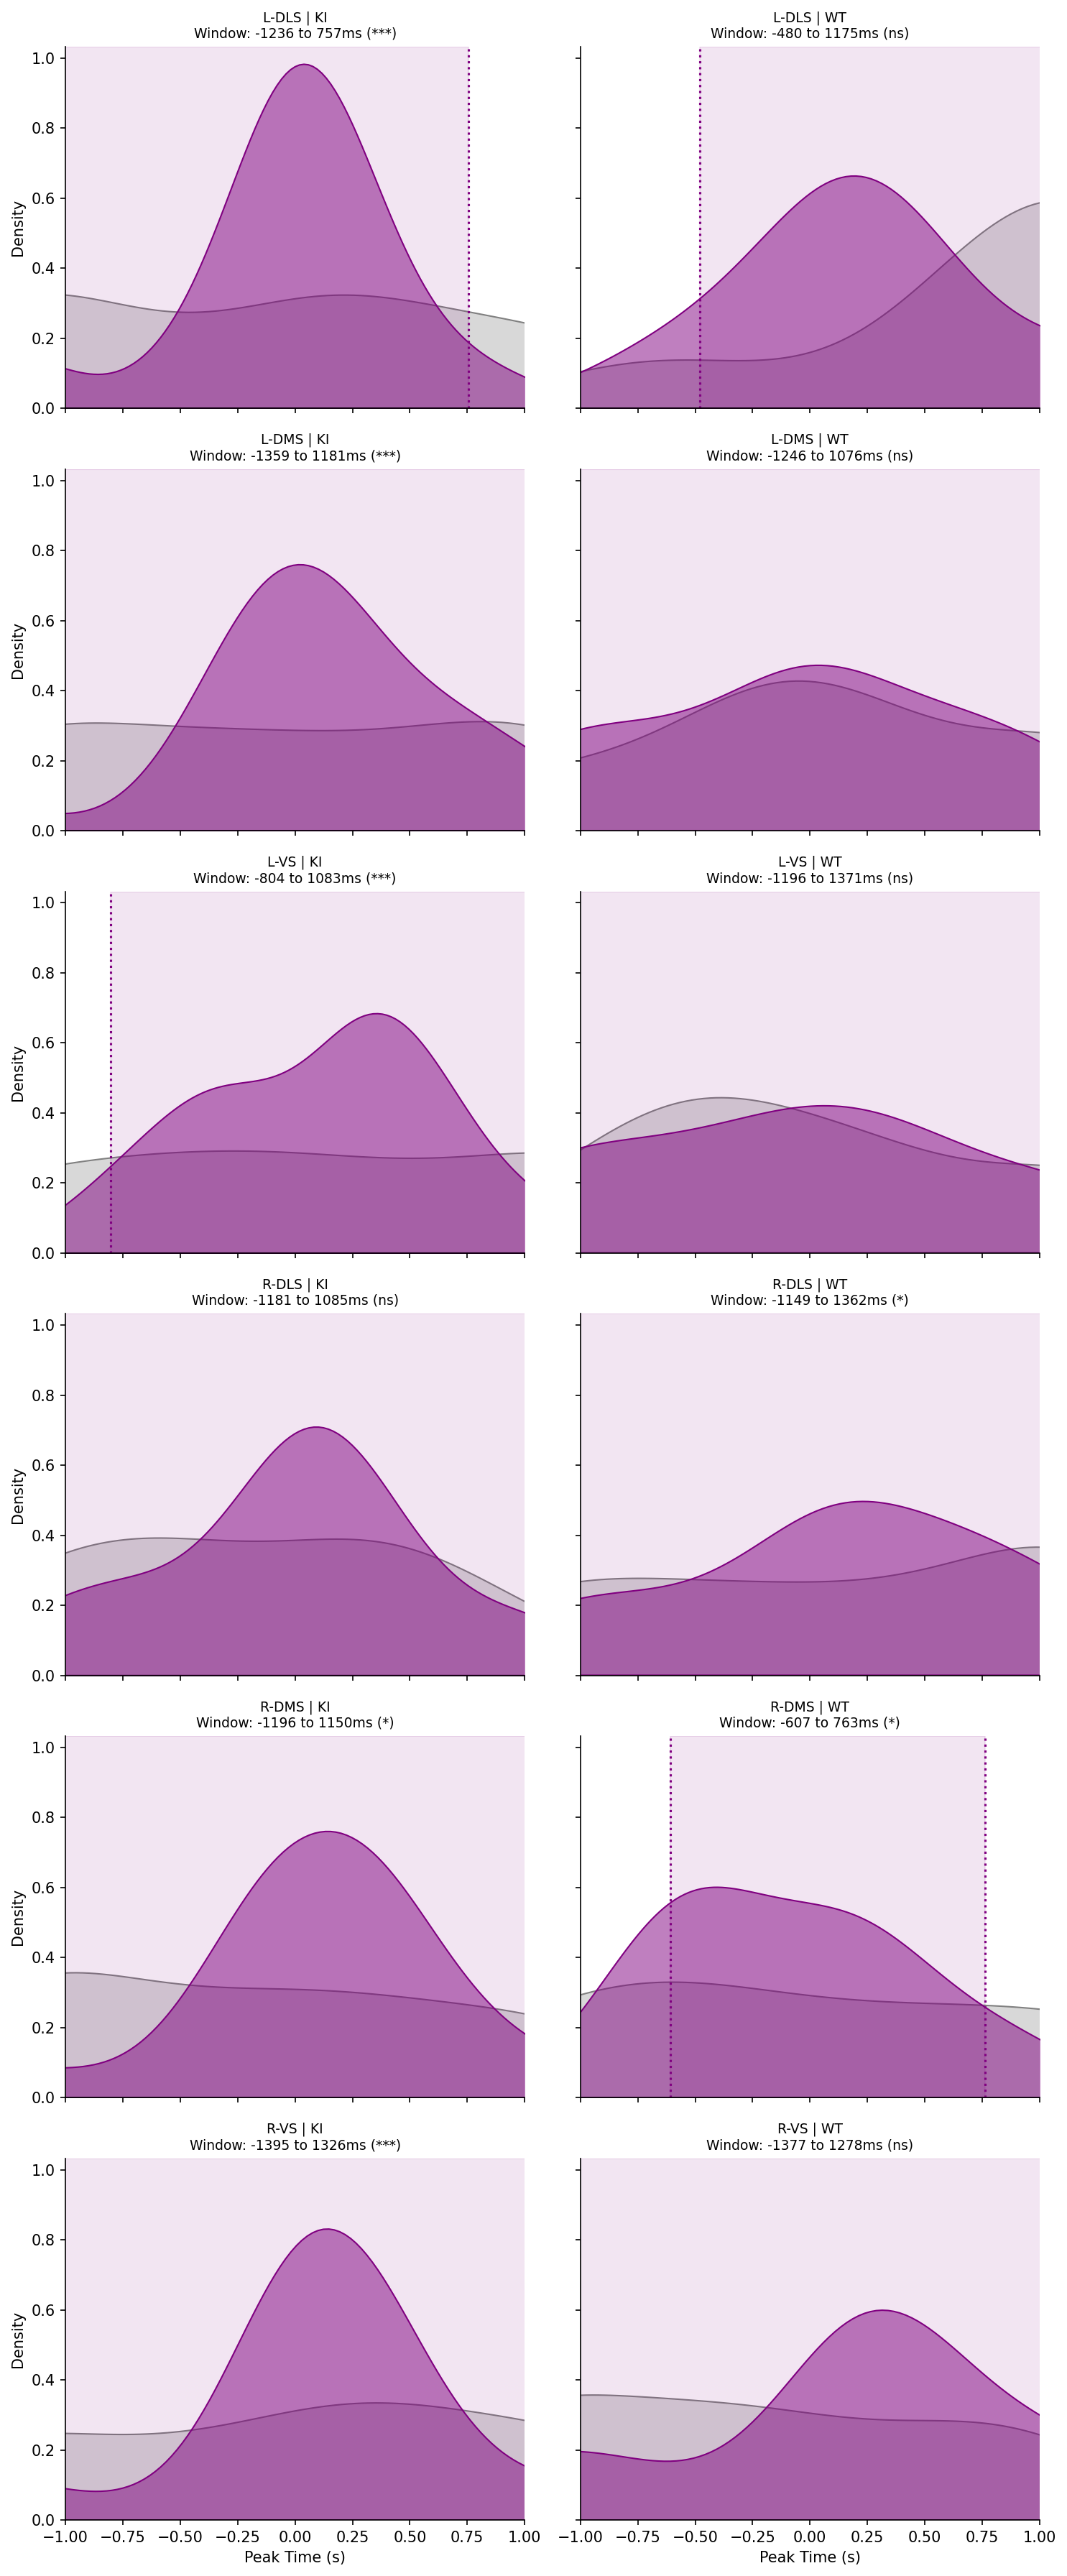


=== TEMPORAL PRECISION & FUNCTIONAL WINDOWS (95% Capture) ===
Condition       | Result          | Center     | Functional Window (s)
--------------------------------------------------------------------------------
L-DLS|KI        | TIME-LOCKED     | +38ms      | [-1.236, +0.757]
L-DLS|WT        | RANDOM          | +207ms     | [-0.480, +1.175]
L-DMS|KI        | TIME-LOCKED     | +119ms     | [-1.359, +1.181]
L-DMS|WT        | RANDOM          | +25ms      | [-1.246, +1.076]
L-VS|KI         | TIME-LOCKED     | +257ms     | [-0.804, +1.083]
L-VS|WT         | RANDOM          | -44ms      | [-1.196, +1.371]
R-DLS|KI        | RANDOM          | +69ms      | [-1.181, +1.085]
R-DLS|WT        | TIME-LOCKED     | +157ms     | [-1.149, +1.362]
R-DMS|KI        | TIME-LOCKED     | +182ms     | [-1.196, +1.150]
R-DMS|WT        | TIME-LOCKED     | -100ms     | [-0.607, +0.763]
R-VS|KI         | TIME-LOCKED     | +157ms     | [-1.395, +1.326]
R-VS|WT         | RANDOM          | +276ms     | [-1.377, +

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# 1. CONFIGURATION
# ==========================================
WINDOW_SEC = 1.5           
MIN_TRIALS_FOR_STATS = 100 
CAPTURE_PERCENTILE = 95    # We want the window that captures this % of peaks

# ==========================================
# 2. VARIANCE ANALYSIS
# ==========================================
print(f"Comparing Peak Time Variance (Actual vs. Shuffle)...")

results = {} 

unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

fig, axes = plt.subplots(
    nrows=len(unique_regions), ncols=len(unique_genos), 
    figsize=(5 * len(unique_genos), 4 * len(unique_regions)),
    dpi=150, sharex=True, sharey=True
)

if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

for r_idx, region in enumerate(unique_regions):
    for c_idx, geno in enumerate(unique_genos):
        ax = axes[r_idx, c_idx]
        syll_data = data_buckets[geno].get(region, {})
        
        if not syll_data:
            ax.text(0.5, 0.5, "No Data", ha='center', va='center'); continue

        peaks_actual = []
        peaks_shuffle = []
        
        # Get Time Vector
        first_key = list(syll_data.keys())[0]
        sample_trace = syll_data[first_key][0][1] 
        n_time = len(sample_trace)
        time_vec = np.linspace(-WINDOW_SEC, WINDOW_SEC, n_time)
        
        for syll, session_list in syll_data.items():
            total_trials = sum(item[0] for item in session_list)
            if total_trials < MIN_TRIALS_FOR_STATS: continue
            
            weighted_actual = np.zeros_like(session_list[0][1])
            weighted_shuffle = np.zeros_like(session_list[0][2])
            
            for n, act, shuff in session_list:
                weighted_actual += act * n
                weighted_shuffle += shuff * n
            
            # 1. Actual Peak Time
            mean_act = weighted_actual / total_trials
            idx_act = np.argmax(np.abs(mean_act))
            peaks_actual.append(time_vec[idx_act])
            
            # 2. Shuffle Peak Time
            mean_shuff = weighted_shuffle / total_trials
            idx_shuff = np.argmax(np.abs(mean_shuff))
            peaks_shuffle.append(time_vec[idx_shuff])
            
        if not peaks_actual:
            ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center'); continue
            
        peaks_actual = np.array(peaks_actual)
        peaks_shuffle = np.array(peaks_shuffle)
        
        # --- B. STATS & WINDOW CALCULATION ---
        # Levene's Test
        stat, p_levene = stats.levene(peaks_actual, peaks_shuffle)
        
        # Functional Window (The 95% Capture Range)
        # We calculate the 2.5th and 97.5th percentiles of the actual peaks
        lower_p = (100 - CAPTURE_PERCENTILE) / 2
        upper_p = 100 - lower_p
        
        win_start = np.percentile(peaks_actual, lower_p)
        win_end = np.percentile(peaks_actual, upper_p)
        
        # Std & Latency
        std_act = np.std(peaks_actual)
        std_shuff = np.std(peaks_shuffle)
        latency = np.median(peaks_actual)
        
        is_tighter = std_act < std_shuff
        
        results[f"{region}|{geno}"] = (std_act, std_shuff, latency, p_levene, is_tighter, win_start, win_end)
        
        # --- C. VISUALIZATION ---
        sns.kdeplot(peaks_shuffle, ax=ax, color="gray", fill=True, alpha=0.3, label="Null")
        sns.kdeplot(peaks_actual, ax=ax, color="purple", fill=True, alpha=0.5, label="Actual")
        
        # Draw the Functional Window
        ax.axvline(win_start, color="purple", linestyle=":", linewidth=1.5)
        ax.axvline(win_end, color="purple", linestyle=":", linewidth=1.5)
        # Highlight the area
        ax.axvspan(win_start, win_end, color="purple", alpha=0.1)
        
        sig_char = "***" if p_levene < 0.001 else ("*" if p_levene < 0.05 else "ns")
        ax.set_title(f"{region} | {geno}\nWindow: {win_start*1000:.0f} to {win_end*1000:.0f}ms ({sig_char})", fontsize=9)
        
        if c_idx == 0: ax.set_ylabel("Density")
        if r_idx == len(unique_regions)-1: ax.set_xlabel("Peak Time (s)")
        
        ax.set_xlim(-1.0, 1.0)
        sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# --- REPORT ---
print(f"\n=== TEMPORAL PRECISION & FUNCTIONAL WINDOWS ({CAPTURE_PERCENTILE}% Capture) ===")
print(f"{'Condition':<15} | {'Result':<15} | {'Center':<10} | {'Functional Window (s)'}")
print("-" * 80)

for key, (s_act, s_null, lat, p, tight, w_start, w_end) in results.items():
    if p < 0.05 and tight:
        status = "TIME-LOCKED"
    elif p < 0.05 and not tight:
        status = "DIFF (Broad)"
    else:
        status = "RANDOM"
    
    lat_str = f"{lat*1000:+.0f}ms"
    win_str = f"[{w_start:+.3f}, {w_end:+.3f}]"
    
    print(f"{key:<15} | {status:<15} | {lat_str:<10} | {win_str}")

### The "Responsiveness" Test (Signal vs. Baseline)

Scanning 19 sessions for Responsiveness...

=== HYPOTHESIS TEST: Response ((0.0, 0.4)s) vs Baseline ((-1.0, -0.5)s) ===
Condition            | N_Trials | Delta (Z)  | Wilcoxon p-value
----------------------------------------------------------------------
L-DLS-L|KI           | 9342     | +0.0901     | 2.85e-20 (***)
L-DLS-L|WT           | 3448     | +0.0567     | 2.73e-06 (***)
L-DMS-L|KI           | 15851    | -0.1236     | 2.72e-29 (***)
L-DMS-L|WT           | 7133     | -0.0982     | 4.29e-15 (***)
L-VS-L|KI            | 10752    | -0.1538     | 1.70e-23 (***)
L-VS-L|WT            | 8987     | -0.0292     | 2.19e-01 (ns)
R-DLS-R|KI           | 5277     | +0.0561     | 2.96e-04 (***)
R-DLS-R|WT           | 8985     | +0.0222     | 2.06e-04 (***)
R-DMS-R|KI           | 10810    | -0.1950     | 2.88e-45 (***)
R-DMS-R|WT           | 3191     | -0.1363     | 2.06e-10 (***)
R-VS-R|KI            | 15447    | -0.2157     | 2.56e-63 (***)
R-VS-R|WT            | 11533    | -0.0917     | 4.86e

/tmp/ipykernel_596252/226697629.py:170: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


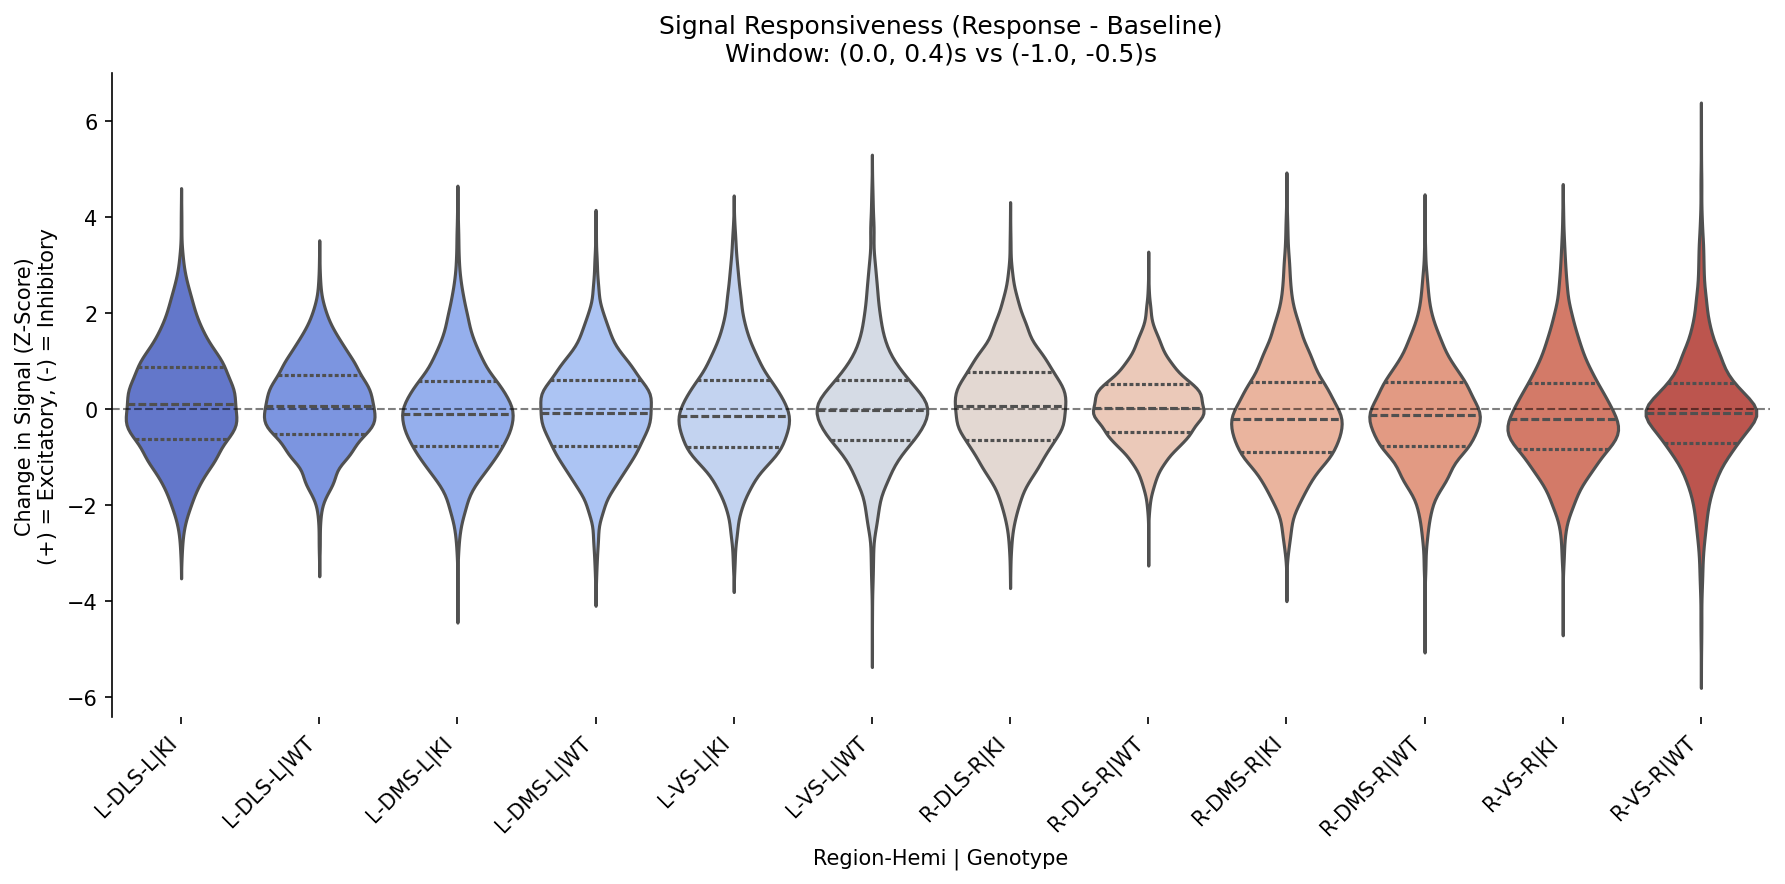

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# Windows defined in SECONDS relative to onset
BASE_WIN = (-1.0, -0.5)   # Baseline window
RESP_WIN = (0.0, 0.4)     # Response window

# Filters
MIN_TRIALS_FOR_STATS = 100
TARGET_ORIG_LETTER = "G"  # Only Green channel
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}
IGNORE_HEMIS = {"UNK", None, "nan"}

# ==========================================
# 2. AGGREGATION (Split by Hemisphere)
# ==========================================
# bucket[condition] = {"base": [], "resp": []}
paired_data = defaultdict(lambda: {"base": [], "resp": []})

print(f"Scanning {len(sessions)} sessions for Responsiveness...")

for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    
    # Convert windows to Frames
    base_start = int(BASE_WIN[0] * fs)
    base_end   = int(BASE_WIN[1] * fs)
    resp_start = int(RESP_WIN[0] * fs)
    resp_end   = int(RESP_WIN[1] * fs)
    
    # Onsets
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    if len(onset_indices) == 0: continue
    
    # Signal Extraction
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        # 1. Filter Color
        if info.get("orig_letter") != TARGET_ORIG_LETTER: continue
        
        # 2. Filter Region
        region = str(info.get("brain_reg", "UNK")).strip()
        if region in IGNORE_REGIONS: continue
            
        # 3. Filter/Clean Hemisphere (THE FIX)
        hemi = str(info.get("hemisphere", "UNK")).strip()
        # Normalize
        if hemi in ["Left", "left", "L"]: hemi = "L"
        elif hemi in ["Right", "right", "R"]: hemi = "R"
        
        if hemi in IGNORE_HEMIS: continue
            
        # Select Column
        col_name = None
        if f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        
        if col_name is None: continue

        signal_data = df[col_name].to_numpy()
        
        # Create Key: "Region-Hemi | Genotype"
        # This forces the plotter to split them
        key = f"{region}-{hemi}|{geno}"
        
        max_idx = len(signal_data)
        
        for idx in onset_indices:
            # Check bounds
            if (idx + base_start < 0) or (idx + resp_end >= max_idx):
                continue
                
            # [FIX] Use nanmean to handle manual exclusions
            # Slice the data
            base_slice = signal_data[idx + base_start : idx + base_end]
            resp_slice = signal_data[idx + resp_start : idx + resp_end]
            
            # Check if slices are completely empty (all NaNs)
            if np.isnan(base_slice).all() or np.isnan(resp_slice).all():
                continue
                
            # Calculate means ignoring NaNs
            val_base = np.nanmean(base_slice)
            val_resp = np.nanmean(resp_slice)
            
            # Double check we didn't get a NaN output (redundant but safe)
            if np.isnan(val_base) or np.isnan(val_resp):
                continue
            
            paired_data[key]["base"].append(val_base)
            paired_data[key]["resp"].append(val_resp)

# ==========================================
# 3. STATISTICS & PLOTTING
# ==========================================
results = {}
sorted_keys = sorted(paired_data.keys())

print(f"\n=== HYPOTHESIS TEST: Response ({RESP_WIN}s) vs Baseline ({BASE_WIN}s) ===")
print(f"{'Condition':<20} | {'N_Trials':<8} | {'Delta (Z)':<10} | {'Wilcoxon p-value'}")
print("-" * 70)

plot_data = []

for key in sorted_keys:
    base = np.array(paired_data[key]["base"])
    resp = np.array(paired_data[key]["resp"])
    
    if len(base) < MIN_TRIALS_FOR_STATS: continue
    
    # 1. Wilcoxon Signed-Rank Test (Paired)
    stat, p = stats.wilcoxon(resp, base)
    
    # 2. Effect Size (Median Difference)
    delta = np.median(resp - base)
    
    results[key] = (p, delta, len(base))
    
    # Text Report
    sig_str = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    print(f"{key:<20} | {len(base):<8} | {delta:+.4f}     | {p:.2e} ({sig_str})")
    
    # Store for plotting (Downsample if huge)
    diffs = resp - base
    if len(diffs) > 5000: 
        diffs = np.random.choice(diffs, 5000, replace=False)
        
    for val in diffs:
        plot_data.append({
            "Condition": key, 
            "Signal Change (Z)": val
        })

# --- VISUALIZATION ---
if plot_data:
    df_plot = pd.DataFrame(plot_data)
    
    plt.figure(figsize=(12, 6), dpi=150) # Made wider for more categories
    
    plt.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
    
    sns.violinplot(
        data=df_plot, 
        x="Condition", 
        y="Signal Change (Z)", 
        palette="coolwarm", 
        inner="quartile",
        linewidth=1.5
    )
    
    plt.title(f"Signal Responsiveness (Response - Baseline)\nWindow: {RESP_WIN}s vs {BASE_WIN}s")
    plt.ylabel(f"Change in Signal (Z-Score)\n(+) = Excitatory, (-) = Inhibitory")
    plt.xlabel("Region-Hemi | Genotype")
    
    # Rotate labels if they get too long
    plt.xticks(rotation=45, ha='right')
    
    sns.despine(bottom=True)
    plt.tight_layout()
    plt.show()
else:
    print("No data available for plotting.")

### The "Syllable Specificity" Test (Kruskal-Wallis ANOVA)

Scanning 19 sessions for Specificity Analysis...

=== SYLLABLE SPECIFICITY (Kruskal-Wallis ANOVA) ===
Condition       | Test Type    | H-Stat     | p-value    | Result
---------------------------------------------------------------------------
L-DLS|KI        | Magnitude    | 70.4       | 5.9e-06   | ***
                | Signed       | 94.3       | 1.1e-09   | ***
---------------------------------------------------------------------------
L-DLS|WT        | Magnitude    | 2.5        | 2.8e-01   | ns
                | Signed       | 3.0        | 2.2e-01   | ns
---------------------------------------------------------------------------
L-DMS|KI        | Magnitude    | 37.4       | 1.7e-01   | ns
                | Signed       | 171.7      | 8.2e-22   | ***
---------------------------------------------------------------------------
L-DMS|WT        | Magnitude    | 91.2       | 4.6e-11   | ***
                | Signed       | 107.2      | 6.2e-14   | ***
-----------------------------------

/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.p

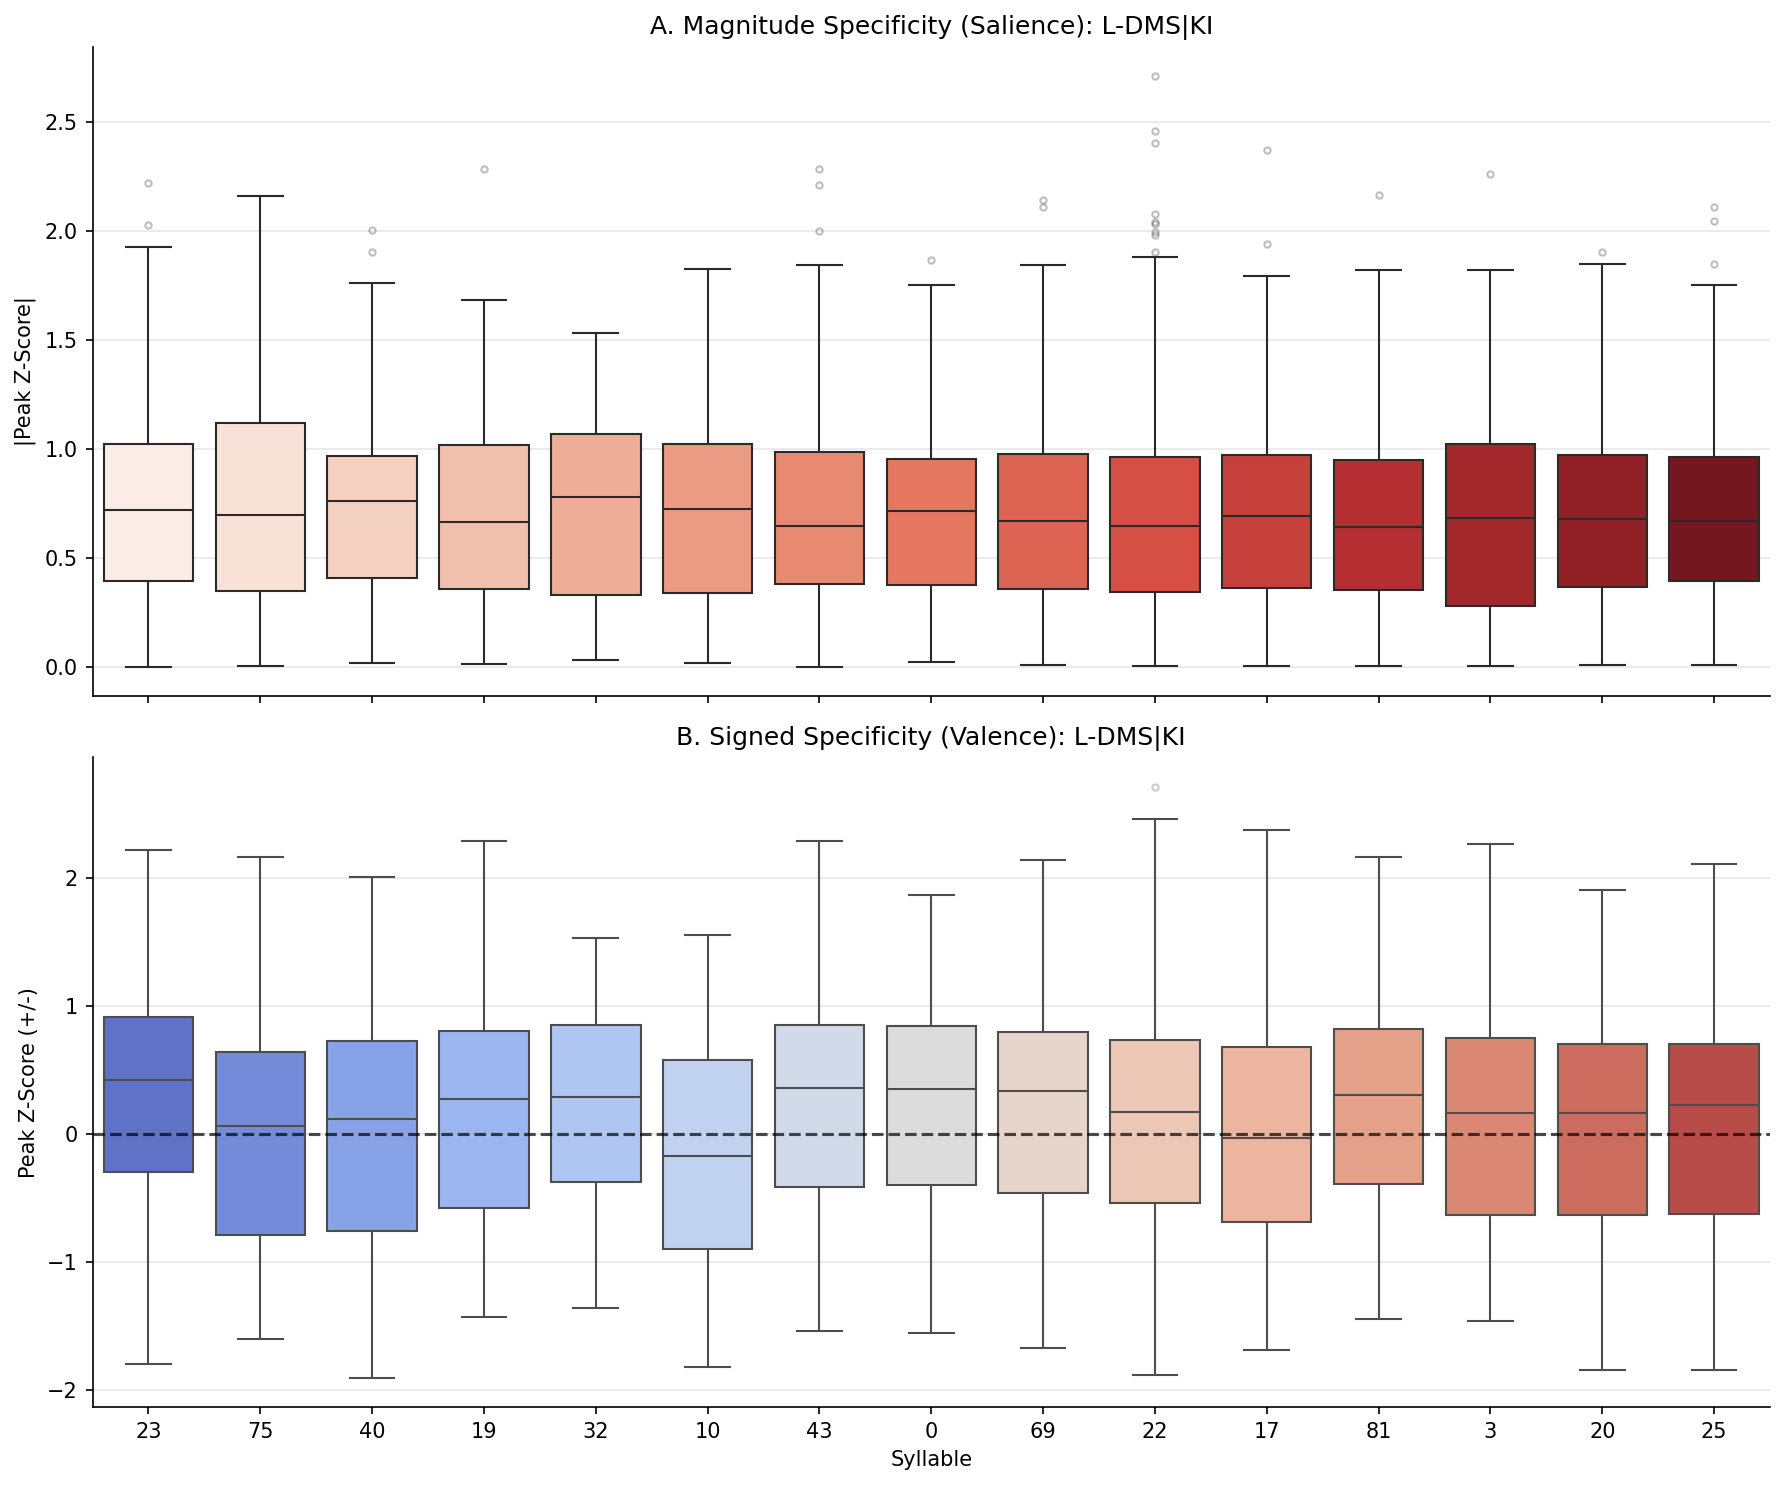

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
WINDOW_SECONDS = 0.4       # 0-400ms window
MIN_TRIALS = 100           # Drop rare syllables
REMOVE_IMMEDIATE = True    # Drop artifacts < 25ms

# --- NORMALIZATION ---
USE_ROBUST_Z = True        # Use Median/MAD (Recommended)

# --- DATA SELECTION ---
TARGET_ORIG_LETTER = "G"
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# ==========================================
# 2. AGGREGATION
# ==========================================
# bucket[condition][syllable] = [list of signed peak values]
data_buckets = defaultdict(lambda: defaultdict(list))

print(f"Scanning {len(sessions)} sessions for Specificity Analysis...")

for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    window_frames = int(WINDOW_SECONDS * fs)
    
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    syllable_array = df["syllable"].to_numpy()
    
    # Signals
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        if info.get("orig_letter") != TARGET_ORIG_LETTER: continue
        region = info.get("brain_reg", "UNK")
        if region in IGNORE_REGIONS: continue
            
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        if col_name is None: continue

        signal_data = df[col_name].to_numpy()
        
        # Robust Baseline
        if USE_ROBUST_Z and "dff" in col_name:
            sess_med = np.nanmedian(signal_data)
            sess_mad = np.nanmedian(np.abs(signal_data - sess_med)) * 1.4826
            if sess_mad == 0: sess_mad = 1.0
        
        key = f"{region}|{geno}"
        
        for idx in onset_indices:
            if idx + window_frames >= len(signal_data): continue
            
            segment = signal_data[idx : idx + window_frames]
            
            # FIND PEAK (Max absolute deviation)
            # We want the biggest event, whether it's a dip or peak
            peak_idx = np.argmax(np.abs(segment))
            peak_val = segment[peak_idx]
            
            # Timing Check
            peak_time = peak_idx / fs 
            if REMOVE_IMMEDIATE and peak_time < 0.025: continue

            # Normalize
            if USE_ROBUST_Z and "dff" in col_name:
                final_val = (peak_val - sess_med) / sess_mad
            else:
                final_val = peak_val

            data_buckets[key][syllable_array[idx]].append(final_val)

# ==========================================
# 3. STATISTICAL TESTS (Two-Part)
# ==========================================
print(f"\n=== SYLLABLE SPECIFICITY (Kruskal-Wallis ANOVA) ===")
print(f"{'Condition':<15} | {'Test Type':<12} | {'H-Stat':<10} | {'p-value':<10} | {'Result'}")
print("-" * 75)

plot_data = []

for key, syll_dict in sorted(data_buckets.items()):
    # Filter valid syllables
    valid_signed = [] # [ [val, val...], [val, val...] ]
    valid_abs = []    # [ [|val|, |val|...], ... ]
    labels = []
    
    for syll, values in syll_dict.items():
        if len(values) >= MIN_TRIALS:
            arr = np.array(values)
            valid_signed.append(arr)
            valid_abs.append(np.abs(arr))
            labels.append(syll)
            
            # Store summary for plotting later
            plot_data.append({
                "Condition": key,
                "Syllable": str(syll),
                "Mean_Signed": np.mean(arr),
                "Mean_Abs": np.mean(np.abs(arr)),
                "Values_Signed": arr,
                "Values_Abs": np.abs(arr),
                "Count": len(arr)
            })
            
    if len(valid_signed) < 2: continue
        
    # TEST 1: MAGNITUDE (|Z|)
    h_abs, p_abs = stats.kruskal(*valid_abs)
    sig_abs = "***" if p_abs < 0.001 else ("*" if p_abs < 0.05 else "ns")
    print(f"{key:<15} | {'Magnitude':<12} | {h_abs:<10.1f} | {p_abs:.1e}   | {sig_abs}")
    
    # TEST 2: SIGNED (Z)
    h_sgn, p_sgn = stats.kruskal(*valid_signed)
    sig_sgn = "***" if p_sgn < 0.001 else ("*" if p_sgn < 0.05 else "ns")
    print(f"{'':<15} | {'Signed':<12} | {h_sgn:<10.1f} | {p_sgn:.1e}   | {sig_sgn}")
    print("-" * 75)

# ==========================================
# 4. VISUALIZATION (Fixing Warnings)
# ==========================================
if plot_data:
    # Pick the condition with the most data
    df_meta = pd.DataFrame(plot_data)
    best_cond = df_meta.groupby("Condition")["Count"].sum().idxmax()
    subset = [d for d in plot_data if d["Condition"] == best_cond]
    
    # Sort by Magnitude (Abs)
    subset.sort(key=lambda x: x["Mean_Abs"], reverse=True)
    top_subset = subset[:15]
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), dpi=150, sharex=True)
    
    # --- PLOT A: MAGNITUDE (|Z|) ---
    rows_abs = []
    for item in top_subset:
        for val in item["Values_Abs"]:
            rows_abs.append({"Syllable": item["Syllable"], "|Peak Z|": val})
            
    # FIX: hue="Syllable", legend=False
    sns.boxplot(
        data=pd.DataFrame(rows_abs), 
        x="Syllable", 
        y="|Peak Z|", 
        hue="Syllable",      # <--- NEW
        legend=False,        # <--- NEW
        ax=axes[0], 
        palette="Reds", 
        flierprops={"marker": ".", "alpha":0.3}
    )
    axes[0].set_title(f"A. Magnitude Specificity (Salience): {best_cond}")
    axes[0].set_ylabel("|Peak Z-Score|")
    axes[0].grid(axis='y', alpha=0.3)
    
    # --- PLOT B: SIGNED (Z) ---
    rows_sgn = []
    for item in top_subset:
        for val in item["Values_Signed"]:
            rows_sgn.append({"Syllable": item["Syllable"], "Peak Z": val})
            
    # FIX: hue="Syllable", legend=False
    sns.boxplot(
        data=pd.DataFrame(rows_sgn), 
        x="Syllable", 
        y="Peak Z", 
        hue="Syllable",      # <--- NEW
        legend=False,        # <--- NEW
        ax=axes[1], 
        palette="coolwarm", 
        flierprops={"marker": ".", "alpha":0.3}
    )
    axes[1].axhline(0, color="black", linestyle="--", alpha=0.7)
    axes[1].set_title(f"B. Signed Specificity (Valence): {best_cond}")
    axes[1].set_ylabel("Peak Z-Score (+/-)")
    axes[1].grid(axis='y', alpha=0.3)
    
    sns.despine()
    plt.tight_layout()
    plt.show()

### The "Genotype Divergence" Test (Permutation Strategy)

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re # Needed for region cleaning

# --- THE MISSING IMPORTS ---
from sklearn.metrics.pairwise import nan_euclidean_distances
try:
    from skbio.stats.distance import permanova, DistanceMatrix
except ImportError:
    raise ImportError("Please install scikit-bio: pip install scikit-bio")

# ==========================================
# 1. BUILD THE FINGERPRINT DATAFRAME (df_fp)
# ==========================================
WINDOW_START = 0.0   
WINDOW_END   = 0.5   
MIN_TRIALS   = 10    

rows = []

print(f"Building Fingerprints from {len(sessions)} sessions...")

for s in sessions:
    meta = s.metadata
    aid = meta.get("animal_id", "UNK")
    geno = meta.get("genotype", "UNK")
    if geno in ["UNK", "nan", None]: continue

    df = s.all_data_df
    if df.empty: continue

    # --- [FIX 1] Robust Rate Calculation ---
    if "SystemTimestamp" in df.columns and len(df) > 1:
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            fs = 1 / dt if dt > 0 else 30.0
        else: fs = 30.0
    else: fs = 30.0
    
    # Onsets
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    
    onset_idx = np.flatnonzero(onsets)
    syllables = df["syllable"].to_numpy()
    
    w_start = int(WINDOW_START * fs)
    w_end = int(WINDOW_END * fs)

    # Signal Loop
    sig_meta = meta.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # --- [FIX 2] Prevent "L-L-DLS" ---
        raw_reg = str(info.get("brain_reg", "UNK"))
        hemi = str(info.get("hemisphere", "UNK")).upper()
        
        # Strip existing prefixes to get base name (e.g. "L-DLS" -> "DLS")
        base_reg = re.sub(r"^[LRlr][\s\-_]+", "", raw_reg).strip().upper()
        
        if base_reg in ["UNK", "NONE"]: continue
        
        # Normalize Hemisphere
        short_hemi = "L" if hemi.startswith("L") else ("R" if hemi.startswith("R") else "UNK")
        if short_hemi == "UNK": continue
            
        region_label = f"{short_hemi}-{base_reg}"
        
        # Data Column
        col = None
        if f"{sig_key}_zscore_datta" in df.columns: col = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col = f"{sig_key}_zscore"
        elif f"{sig_key}_dff" in df.columns: col = f"{sig_key}_dff"
        
        if not col: continue
        sig_data = df[col].to_numpy()

        # Aggregation
        syll_responses = {} 
        
        for idx in onset_idx:
            syll = syllables[idx]
            if idx + w_end >= len(sig_data): continue
            
            segment = sig_data[idx + w_start : idx + w_end]
            
            # --- [FIX 3] Ignore Excluded Trials ---
            # If segment is all NaNs (manual exclusion), skip it.
            # Do not let it count towards MIN_TRIALS.
            if np.isnan(segment).all(): continue
                
            mean_resp = np.nanmean(segment)
            
            if syll not in syll_responses: syll_responses[syll] = []
            syll_responses[syll].append(mean_resp)
            
        # Store
        for syll, values in syll_responses.items():
            if len(values) >= MIN_TRIALS:
                rows.append({
                    "Animal": aid,
                    "Genotype": geno,
                    "Region": region_label,
                    "Syllable": syll,
                    "Mean_Z": np.nanmean(values),
                    "N_Trials": len(values)
                })

df_fp = pd.DataFrame(rows)
print(f"Generated df_fp with shape: {df_fp.shape}")
print("Regions found:", sorted(df_fp["Region"].unique()))

Building Fingerprints from 19 sessions...
Generated df_fp with shape: (2742, 6)
Regions found: ['L-DLS', 'L-DMS', 'L-VS', 'R-DLS', 'R-DMS', 'R-VS']



--- Running PERMANOVA ---

=== PERMANOVA RESULTS (Greedy) ===
Region   F-Stat  p-value  N  Syllables_Used
 R-DLS 1.260032    0.212  5              74
  L-VS 1.357274    0.420  5              74
 L-DLS 1.123288    0.694  3              66
 R-DMS 0.728823    0.697  3              59
 L-DMS 0.865336    0.806  5              64
  R-VS 0.514504    0.908  6              68


/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.p

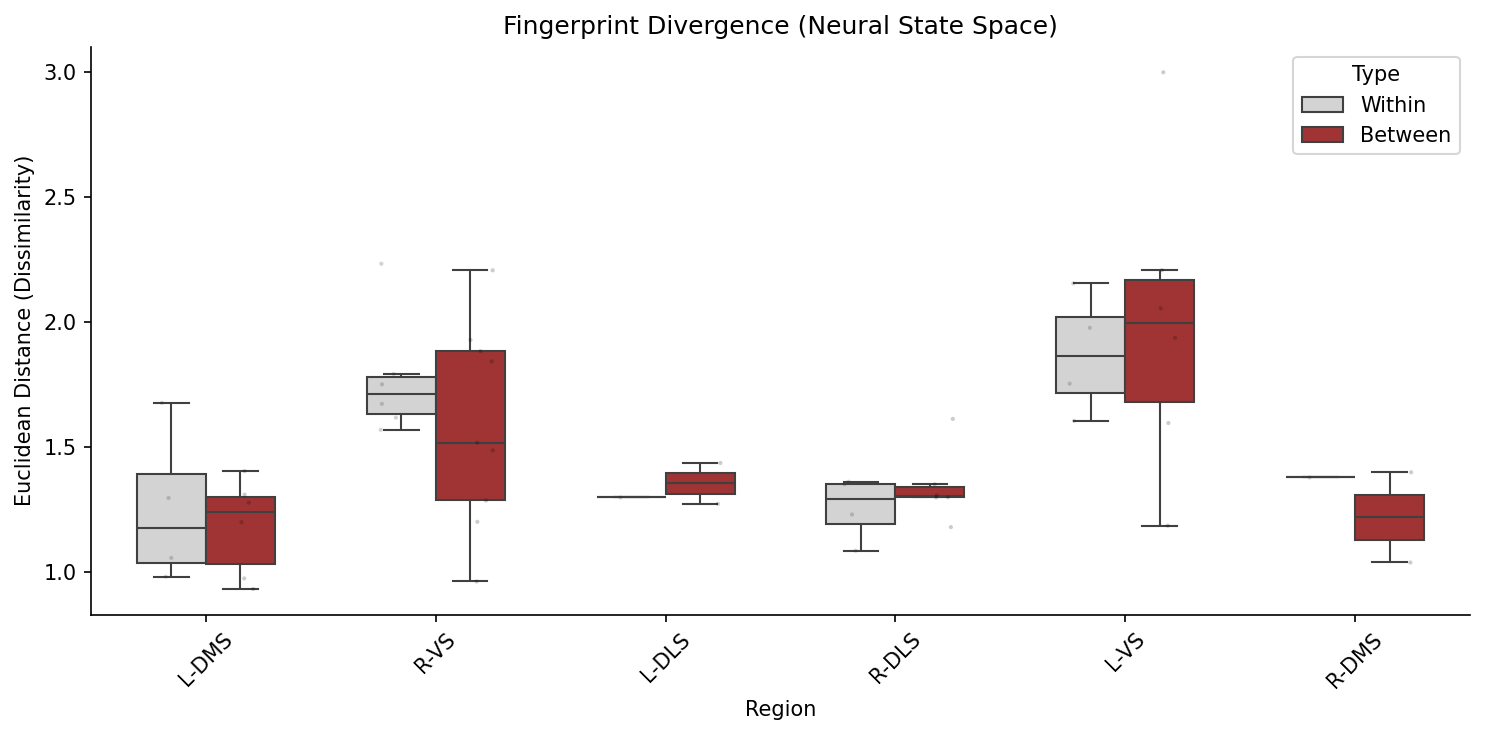

In [11]:
# ==========================================
# 3. GREEDY PERMANOVA (Fixed)
# ==========================================
regions = df_fp["Region"].unique()
results = []
dist_pairs = []

print("\n--- Running PERMANOVA ---")

for reg in regions:
    sub = df_fp[df_fp["Region"] == reg]
    
    # A. Pivot: Create Sparse Matrix
    # Shape: (N_Animals, N_Syllables)
    # A. Pivot
    pivot = sub.pivot_table(index=["Animal", "Genotype"], columns="Syllable", values="Mean_Z")
    pivot = pivot.dropna(thresh=3, axis=0) # Must have at least 3 valid syllables
    
    # --- CHANGE 1: Lower threshold from 4 to 3 ---
    if len(pivot) < 3: 
        print(f"Skipping {reg} (N={len(pivot)}, really too small)")
        continue

    # --- CHANGE 2: Check for Genotype Divergence ---
    # We need at least 1 WT and 1 KI to compare anything
    present_genos = pivot.index.get_level_values("Genotype").unique()
    if len(present_genos) < 2:
        print(f"Skipping {reg} (Only found {present_genos.tolist()})")
        continue

    # B. Greedy Distance Calculation
    X = pivot.values
    
    # This function handles NaNs by ignoring missing coordinates pair-wise
    # (e.g. if Animal A has syll 1,2 and Animal B has 2,3, it calculates dist on syll 2 only)
    D = nan_euclidean_distances(X, X)
    
    # C. Impute "Total Disjoint" Pairs
    # If animals share ZERO syllables, dist is NaN. 
    # Fill with the mean distance of the rest of the matrix (neutral assumption)
    if np.isnan(D).any():
        valid_mean = np.nanmean(D)
        D = np.nan_to_num(D, nan=valid_mean)

    # D. Run PERMANOVA
    ids = pivot.index.get_level_values("Animal").tolist()
    genos = pivot.index.get_level_values("Genotype").tolist()
    
    try:
        # Enforce symmetry (floating point errors) and zero diagonal
        D = (D + D.T) / 2
        np.fill_diagonal(D, 0)
        
        # Scikit-bio Distance Matrix
        dm = DistanceMatrix(D, ids)
        
        # The Stat Test
        stats = permanova(dm, grouping=genos, permutations=999)
        
        results.append({
            "Region": reg,
            "F-Stat": stats["test statistic"],
            "p-value": stats["p-value"],
            "N": stats["sample size"],
            "Syllables_Used": pivot.shape[1] 
        })
        
        # E. Store Pairwise (For visualization)
        # Flatten the distance matrix into pairs
        for i in range(len(D)):
            for j in range(i+1, len(D)):
                g1, g2 = genos[i], genos[j]
                dist_pairs.append({
                    "Region": reg,
                    "Distance": D[i,j],
                    "Type": "Within" if g1 == g2 else "Between"
                })

    except Exception as e:
        print(f"   Error in PERMANOVA {reg}: {e}")

# --- OUTPUT RESULTS ---
if results:
    res_df = pd.DataFrame(results).sort_values("p-value")
    print("\n=== PERMANOVA RESULTS (Greedy) ===")
    print(res_df.to_string(index=False))

if dist_pairs:
    pair_df = pd.DataFrame(dist_pairs)
    plt.figure(figsize=(10, 5), dpi=150)
    
    # Plot
    sns.boxplot(data=pair_df, x="Region", y="Distance", hue="Type", 
                palette={"Within": "lightgrey", "Between": "firebrick"}, 
                showfliers=False, width=0.6)
    
    # Strip plot for detail (optional, can be slow if N is huge)
    sns.stripplot(data=pair_df, x="Region", y="Distance", hue="Type", 
                  dodge=True, color="black", alpha=0.2, size=2, legend=False)
    
    plt.title("Fingerprint Divergence (Neural State Space)")
    plt.ylabel("Euclidean Distance (Dissimilarity)")
    plt.xticks(rotation=45)
    sns.despine()
    plt.tight_layout()
    plt.show()

# Kinematic syllable tests

### Test 1: Vigor-Binned Waveforms (Aggregated Syllables)

Scanning 19 sessions...


/tmp/ipykernel_596252/295119870.py:122: RuntimeWarning: Mean of empty slice
  sess_mean_trace = np.nanmean(trace_stack, axis=0)



=== VIGOR-BINNED WAVEFORMS (Split by Hemi) ===


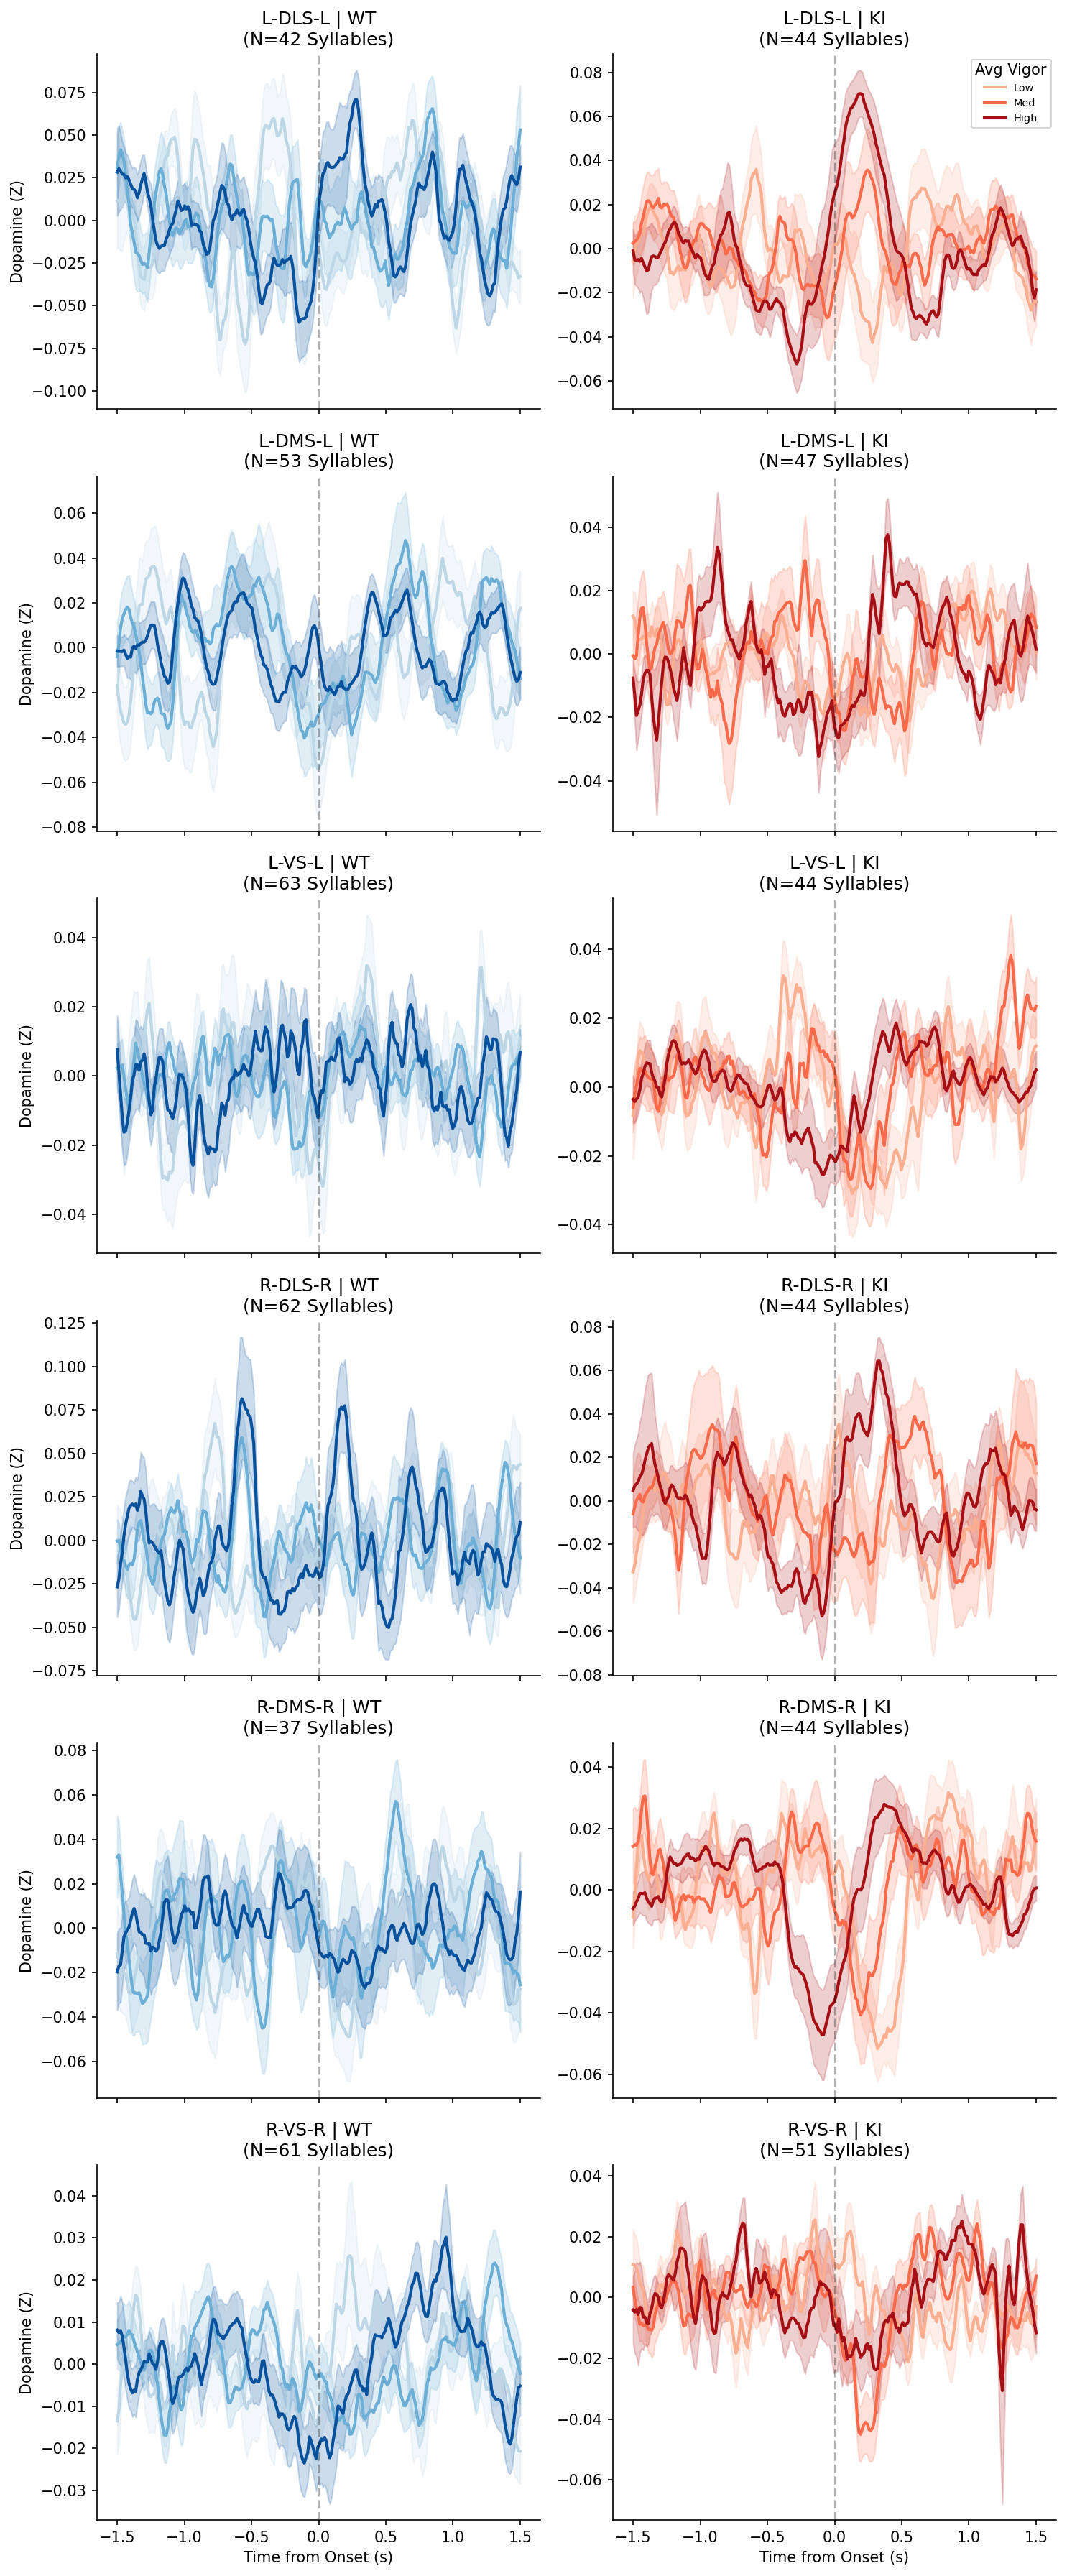

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
DA_WINDOW_SEC = 1.5         
VEL_WINDOW = (0.0, 0.5)     
MIN_TRIALS = 30 # Lowered slightly for split data
TARGET_ORIG_LETTER = "G"
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}
IGNORE_HEMIS = {"UNK", None, "nan"}

# ==========================================
# 2. HELPER
# ==========================================
def apply_bessel_filter(series, fs):
    nyquist = fs / 2.0
    if nyquist <= 1.0: return series
    sos = signal.bessel(1, 1.0 / nyquist, btype="high", output="sos")
    valid_mask = ~np.isnan(series)
    res = np.full_like(series, np.nan)
    if valid_mask.sum() > 10:
        res[valid_mask] = signal.sosfiltfilt(sos, series[valid_mask])
    return res

# ==========================================
# 3. AGGREGATION (Split by Hemi)
# ==========================================
# syll_data[region_hemi][geno][syll] = { ... }
syll_data = defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))

print(f"Scanning {len(sessions)} sessions...")

for session in sessions:
    meta = session.metadata
    geno = meta.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    
    da_frames = int(DA_WINDOW_SEC * fs)
    vel_end = int(VEL_WINDOW[1] * fs)
    
    onsets = df["onset"].fillna(0).astype(bool).to_numpy() if "onset" in df.columns else (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    syllable_array = df["syllable"].to_numpy()
    velocity_array = df["velocity_px_s"].to_numpy()
    
    sig_meta = meta.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # --- FILTERING ---
        color = info.get("orig_letter", "UNK")
        if not color and "fiber_num" in info: # Hotfix
             color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
        if color != TARGET_ORIG_LETTER: continue
            
        base_reg = info.get("brain_reg", "UNK")
        hemi = info.get("hemisphere", "UNK").replace("Left", "L").replace("Right", "R")
        
        if base_reg in IGNORE_REGIONS: continue
        if hemi in IGNORE_HEMIS: continue
            
        # Construct Split Key (e.g. DLS-L)
        split_key = f"{base_reg}-{hemi}"

        col_name = None
        if f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        else: continue

        raw_sig = df[col_name].to_numpy()
        filtered_sig = apply_bessel_filter(raw_sig, fs)
        max_idx = len(filtered_sig)
        
        sess_traces = defaultdict(list)
        sess_vigors = defaultdict(list)
        
        for idx in onset_indices:
            s_da = idx - da_frames
            e_da = idx + da_frames
            e_vel = idx + vel_end
            if s_da < 0 or e_da >= max_idx or e_vel >= max_idx: continue
            
            trace = filtered_sig[s_da : e_da]
            vigor = np.max(velocity_array[idx : e_vel]) 
            
            syll = syllable_array[idx]
            sess_traces[syll].append(trace)
            sess_vigors[syll].append(vigor)
            
        for syll, traces in sess_traces.items():
            vigors = sess_vigors[syll]
            
            # [FIX] Stack first to check validity
            trace_stack = np.array(traces)
            
            # If the entire stack for this syllable is NaN (e.g. happened during artifact), skip it
            if np.isnan(trace_stack).all():
                continue

            # Calculate session-level mean ignoring NaNs
            sess_mean_trace = np.nanmean(trace_stack, axis=0)
            
            # Double check the result isn't all NaN (redundant but safe)
            if np.isnan(sess_mean_trace).all():
                continue
                
            sess_mean_vigor = np.mean(vigors)
            
            # Initialize dict if needed
            if "traces" not in syll_data[split_key][geno][syll]:
                syll_data[split_key][geno][syll] = {'traces': [], 'vigors': [], 'n': 0}
                
            syll_data[split_key][geno][syll]['traces'].append(sess_mean_trace)
            syll_data[split_key][geno][syll]['vigors'].append(sess_mean_vigor)
            syll_data[split_key][geno][syll]['n'] += len(traces)

# ==========================================
# 4. BINNING & PLOTTING
# ==========================================
unique_regions = sorted(syll_data.keys())
# Note: Assuming trace length is consistent (approx 2*da_frames). 
# We create a generic time vector based on the last FS
time_vec = np.linspace(-DA_WINDOW_SEC, DA_WINDOW_SEC, 2*da_frames)

print(f"\n=== VIGOR-BINNED WAVEFORMS (Split by Hemi) ===")

# We create a grid: Rows = Regions(L/R), Cols = Genotypes
fig, axes = plt.subplots(
    nrows=len(unique_regions), ncols=2, 
    figsize=(10, 4*len(unique_regions)), 
    dpi=150, sharex=True, sharey=False # False sharey to see scale differences
)

if len(unique_regions) == 1: axes = np.array([axes])

for i, region in enumerate(unique_regions):
    for j, geno in enumerate(["WT", "KI"]):
        ax = axes[i, j] if len(axes.shape) > 1 else axes[j]
        
        syll_points = []
        for syll, data in syll_data[region][geno].items():
            if data['n'] < MIN_TRIALS: continue
            
            # Check length match (fs variation safety)
            # Resample if needed, or assume close enough for visualization
            tr_stack = np.vstack(data['traces'])
            if tr_stack.shape[1] != len(time_vec):
                 # Simple linear interpolation to match grid
                 tr_stack = np.array([np.interp(np.linspace(0,1,len(time_vec)), np.linspace(0,1,len(t)), t) for t in tr_stack])

            g_trace = np.mean(tr_stack, axis=0)
            g_vigor = np.mean(data['vigors'])
            syll_points.append({'trace': g_trace, 'vigor': g_vigor})
            
        if not syll_points:
            ax.text(0.5, 0.5, "No Data", ha='center'); continue
            
        vigors = [p['vigor'] for p in syll_points]
        p33 = np.percentile(vigors, 33)
        p66 = np.percentile(vigors, 66)
        
        bins = {'Low': [], 'Med': [], 'High': []}
        for p in syll_points:
            if p['vigor'] <= p33: bins['Low'].append(p['trace'])
            elif p['vigor'] <= p66: bins['Med'].append(p['trace'])
            else: bins['High'].append(p['trace'])
            
        colors = {'Low': '#bdd7e7', 'Med': '#6baed6', 'High': '#08519c'} 
        if geno == "KI": colors = {'Low': '#fcae91', 'Med': '#fb6a4a', 'High': '#a50f15'}
        
        for label in ['Low', 'Med', 'High']:
            stack = np.array(bins[label])
            if len(stack) > 0:
                mean_trace = np.mean(stack, axis=0)
                sem_trace = np.std(stack, axis=0) / np.sqrt(len(stack))
                
                ax.plot(time_vec, mean_trace, color=colors[label], linewidth=2, label=label)
                ax.fill_between(time_vec, mean_trace-sem_trace, mean_trace+sem_trace, color=colors[label], alpha=0.2)
        
        ax.axvline(0, color="black", linestyle="--", alpha=0.3)
        ax.set_title(f"{region} | {geno}\n(N={len(syll_points)} Syllables)")
        
        if i == len(unique_regions)-1: ax.set_xlabel("Time from Onset (s)")
        if j == 0: ax.set_ylabel("Dopamine (Z)")
        if i==0 and j==1: ax.legend(title="Avg Vigor", loc='upper right', fontsize='x-small')

sns.despine()
plt.tight_layout()
plt.show()

Test 2: Vigor vs. Valence (Correlation)

Aggregating Signed Dopamine Peaks...
✅ Found 1372 dopamine summary rows.

ANALYSIS: VELOCITY vs. VALENCE | Hemisphere: L


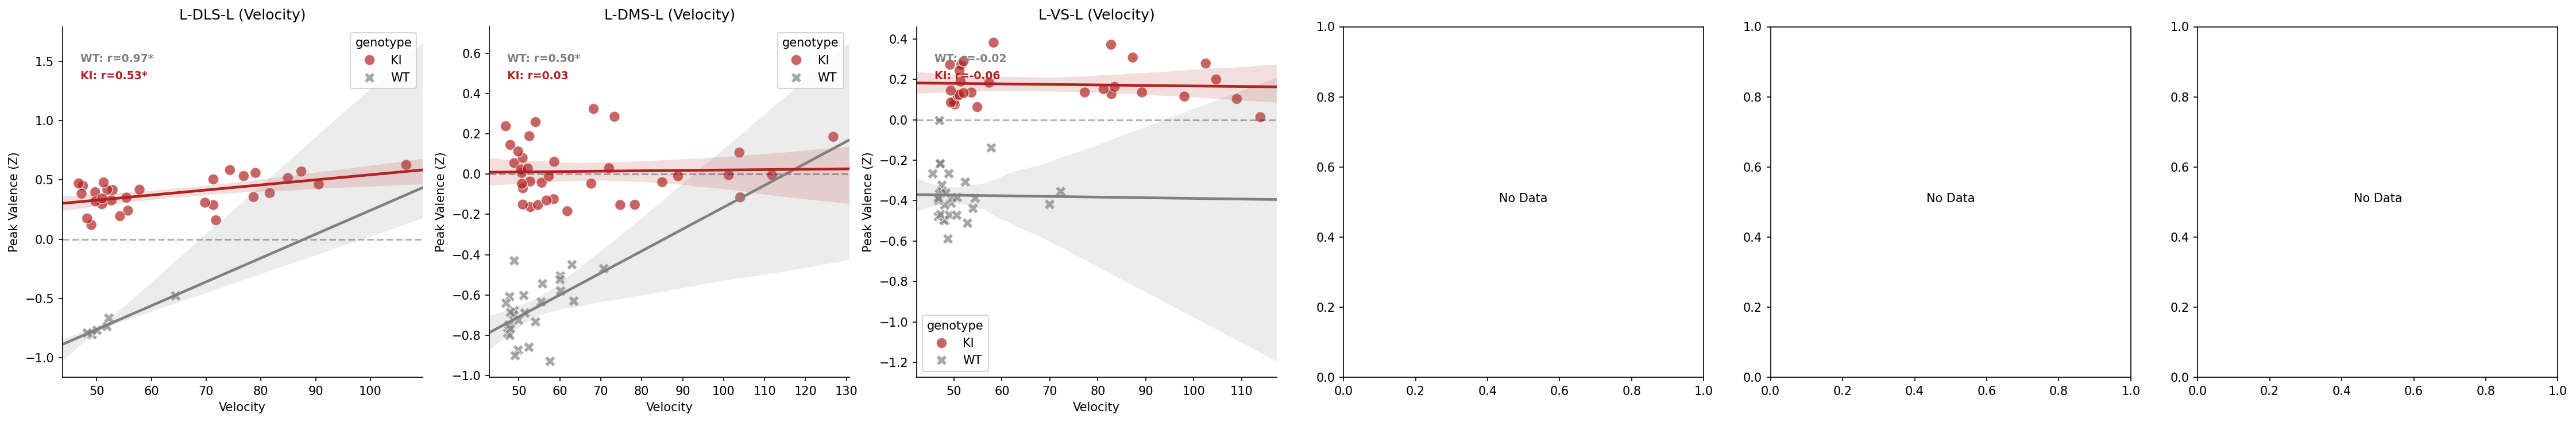


Table 1: Velocity Coupling (L-Hemi)
Region   | Geno | N    | Slope    | Corr (r)   | p-value   
-----------------------------------------------------------------
L-DLS    | WT   | 6    | +0.020   | 0.975      | 9.3e-04 ***
L-DLS    | KI   | 30   | +0.004   | 0.528      | 2.7e-03 **
L-DMS    | WT   | 26   | +0.011   | 0.497      | 9.9e-03 **
L-DMS    | KI   | 35   | +0.000   | 0.029      | 8.7e-01 
L-VS     | WT   | 31   | -0.000   | -0.017     | 9.3e-01 
L-VS     | KI   | 28   | -0.000   | -0.060     | 7.6e-01 

Table 2: Genotype Comparison (L-Hemi)
Region   | WT Slope   | KI Slope   | Diff p-val | Result
-----------------------------------------------------------------
L-DLS    | 0.0201     | 0.0043     | 2.0e-09 *** | DIFFERENT MAP
L-DMS    | 0.0109     | 0.0002     | 8.2e-03 **  | DIFFERENT MAP
L-VS     | -0.0003    | -0.0003    | 9.8e-01 ns  | SAME MAP



ANALYSIS: VELOCITY vs. VALENCE | Hemisphere: R


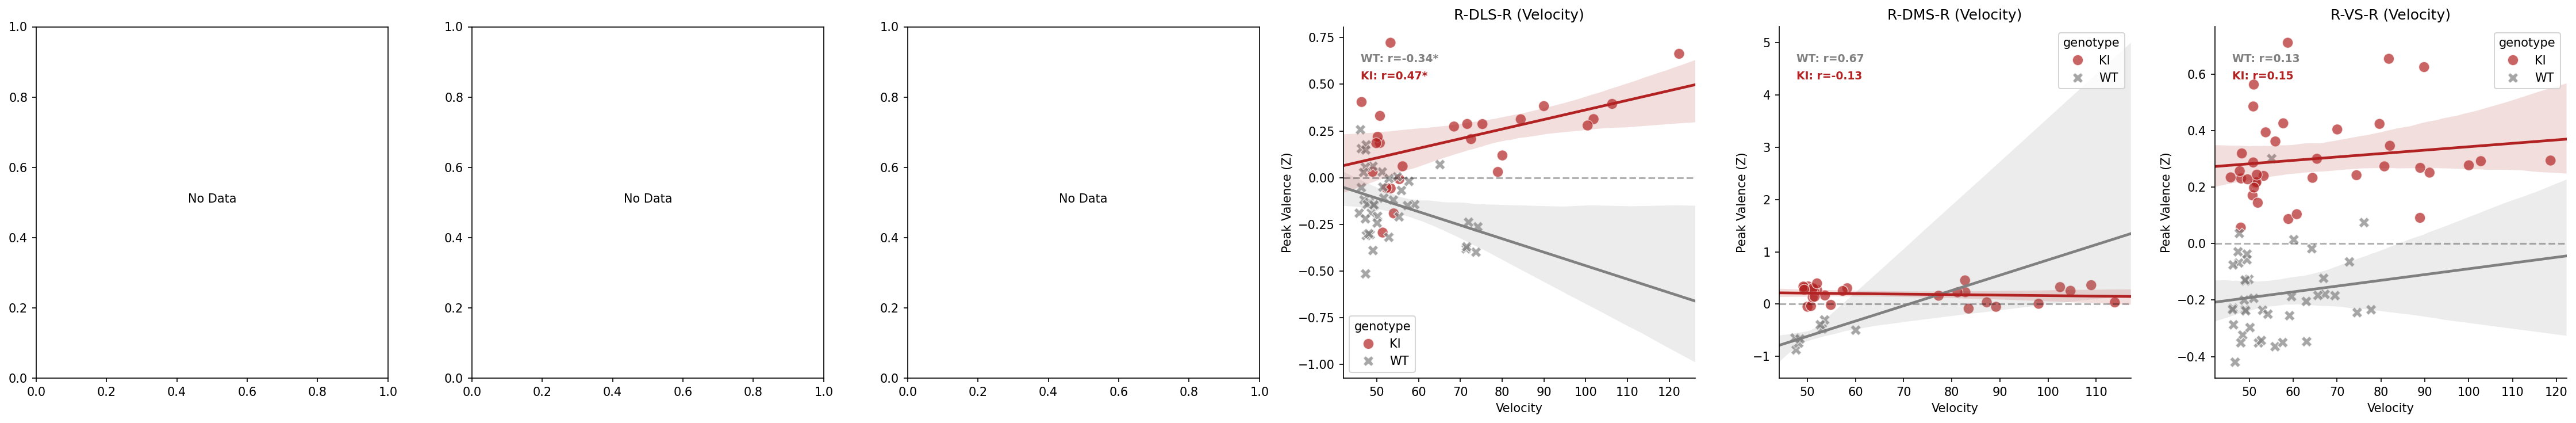


Table 1: Velocity Coupling (R-Hemi)
Region   | Geno | N    | Slope    | Corr (r)   | p-value   
-----------------------------------------------------------------
R-DLS    | WT   | 41   | -0.007   | -0.345     | 2.7e-02 *
R-DLS    | KI   | 25   | +0.005   | 0.473      | 1.7e-02 *
R-DMS    | WT   | 8    | +0.029   | 0.666      | 7.1e-02 
R-DMS    | KI   | 28   | -0.001   | -0.135     | 4.9e-01 
R-VS     | WT   | 41   | +0.002   | 0.133      | 4.1e-01 
R-VS     | KI   | 37   | +0.001   | 0.150      | 3.8e-01 

Table 2: Genotype Comparison (R-Hemi)
Region   | WT Slope   | KI Slope   | Diff p-val | Result
-----------------------------------------------------------------
R-DLS    | -0.0072    | 0.0051     | 9.1e-04 *** | DIFFERENT MAP
R-DMS    | 0.0292     | -0.0010    | 2.5e-02 *   | DIFFERENT MAP
R-VS     | 0.0020     | 0.0012     | 7.6e-01 ns  | SAME MAP



ANALYSIS: ACCELERATION vs. VALENCE | Hemisphere: L


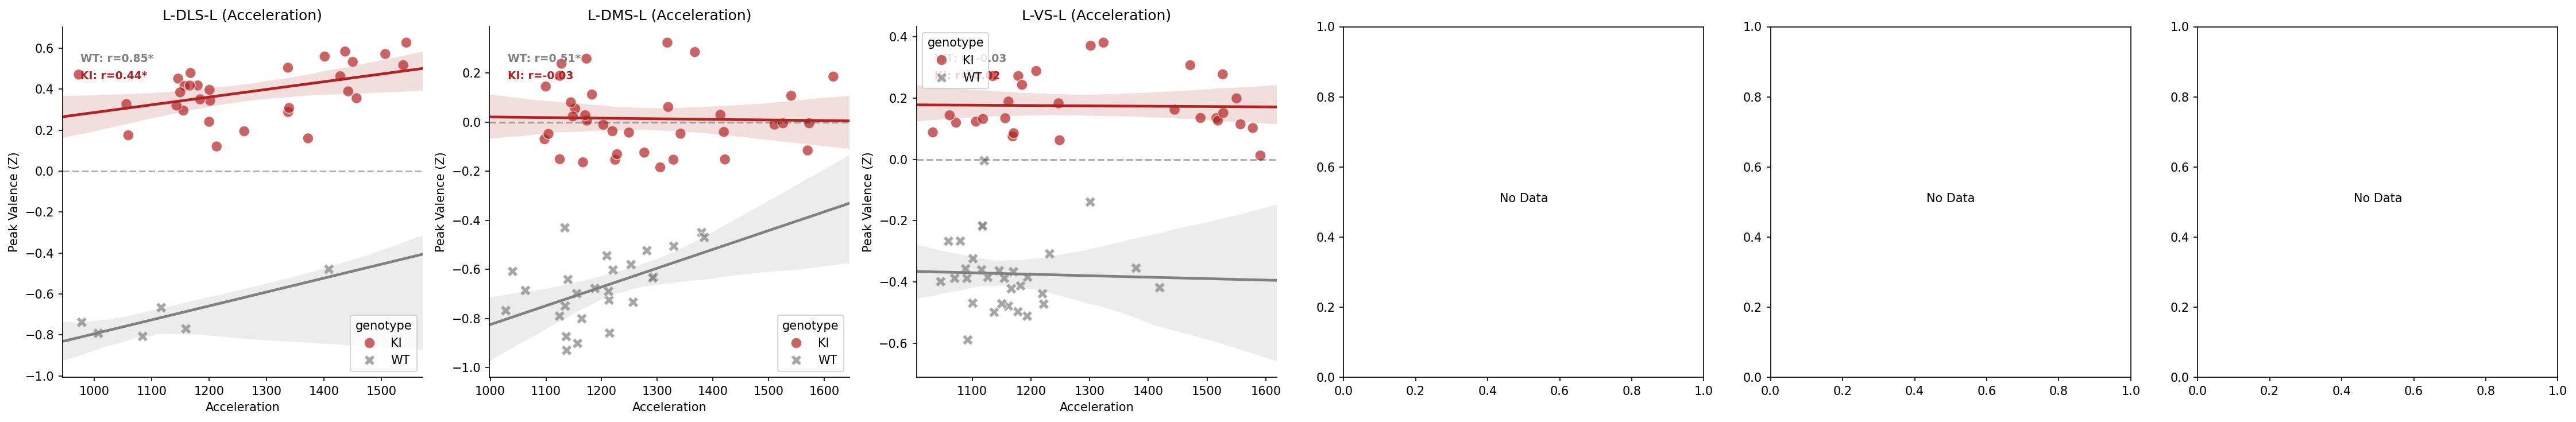


Table 1: Acceleration Coupling (L-Hemi)
Region   | Geno | N    | Slope    | Corr (r)   | p-value   
-----------------------------------------------------------------
L-DLS    | WT   | 6    | +0.001   | 0.851      | 3.1e-02 *
L-DLS    | KI   | 30   | +0.000   | 0.443      | 1.4e-02 *
L-DMS    | WT   | 26   | +0.001   | 0.515      | 7.1e-03 **
L-DMS    | KI   | 35   | -0.000   | -0.028     | 8.7e-01 
L-VS     | WT   | 31   | -0.000   | -0.035     | 8.5e-01 
L-VS     | KI   | 28   | -0.000   | -0.022     | 9.1e-01 

Table 2: Genotype Comparison (L-Hemi)
Region   | WT Slope   | KI Slope   | Diff p-val | Result
-----------------------------------------------------------------
L-DLS    | 0.0007     | 0.0004     | 2.3e-01 ns  | SAME MAP
L-DMS    | 0.0008     | -0.0000    | 8.9e-03 **  | DIFFERENT MAP
L-VS     | -0.0000    | -0.0000    | 8.9e-01 ns  | SAME MAP



ANALYSIS: ACCELERATION vs. VALENCE | Hemisphere: R


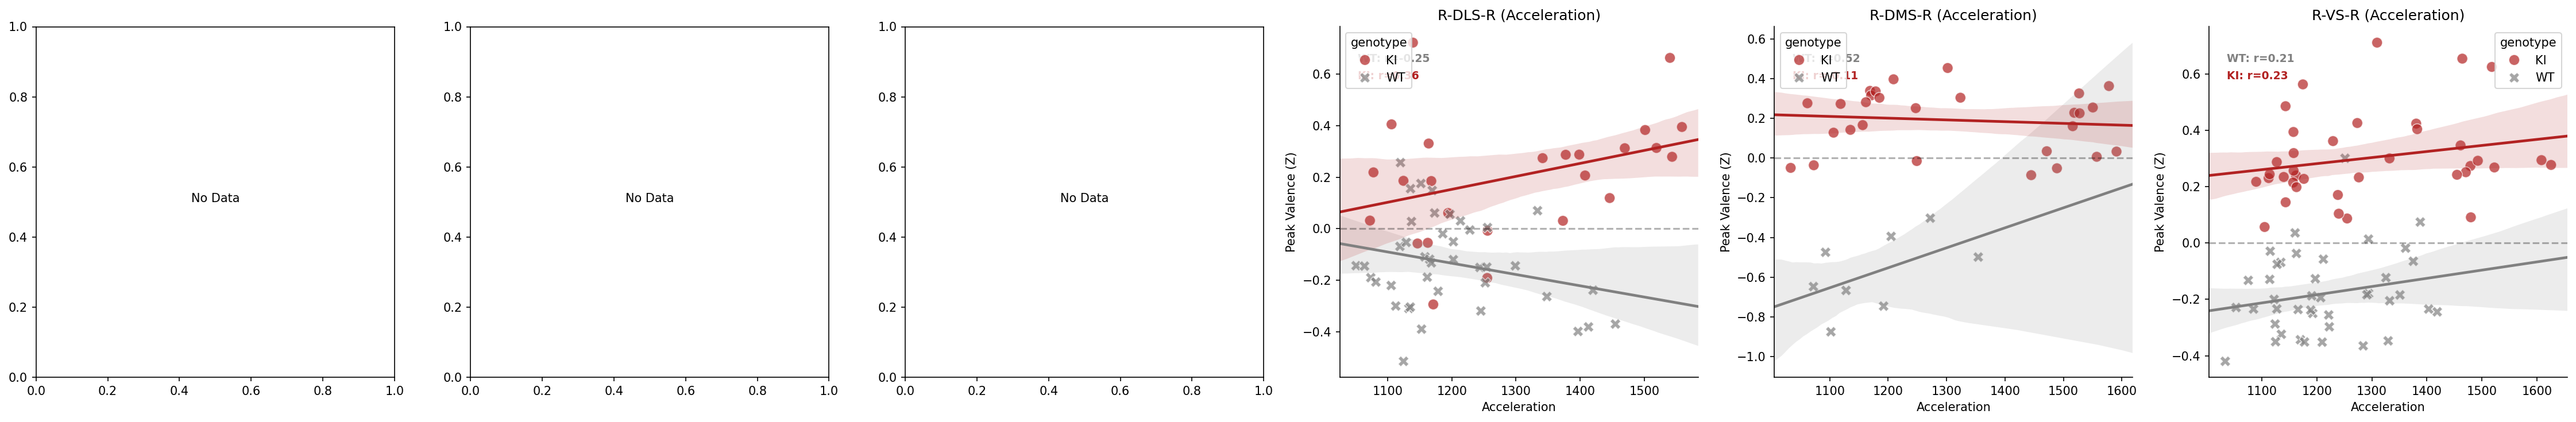


Table 1: Acceleration Coupling (R-Hemi)
Region   | Geno | N    | Slope    | Corr (r)   | p-value   
-----------------------------------------------------------------
R-DLS    | WT   | 41   | -0.000   | -0.249     | 1.2e-01 
R-DLS    | KI   | 25   | +0.001   | 0.356      | 8.1e-02 
R-DMS    | WT   | 8    | +0.001   | 0.518      | 1.9e-01 
R-DMS    | KI   | 28   | -0.000   | -0.107     | 5.9e-01 
R-VS     | WT   | 41   | +0.000   | 0.207      | 1.9e-01 
R-VS     | KI   | 37   | +0.000   | 0.226      | 1.8e-01 

Table 2: Genotype Comparison (R-Hemi)
Region   | WT Slope   | KI Slope   | Diff p-val | Result
-----------------------------------------------------------------
R-DLS    | -0.0004    | 0.0005     | 1.5e-02 *   | DIFFERENT MAP
R-DMS    | 0.0010     | -0.0001    | 1.2e-01 ns  | SAME MAP
R-VS     | 0.0003     | 0.0002     | 7.8e-01 ns  | SAME MAP




In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# We test BOTH Velocity and Acceleration in one go
KINEMATIC_FEATURES = [
    ('velocity_p95_median', 'Velocity'),
    ('accel_p95_median', 'Acceleration')
]

DOPAMINE_METRIC = 'Peak Z'
WINDOW_SECONDS = 0.3 
MIN_TRIALS = 10            
USE_ROBUST_Z = True

TARGET_ORIG_LETTER = "G"
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}
IGNORE_HEMIS = {"UNK", None, "nan"}

# ==========================================
# 2. PREPARE DOPAMINE DATA (Split Hemi)
# ==========================================
dopamine_rows = []
print(f"Aggregating Signed Dopamine Peaks...")

for session in sessions:
    meta = session.metadata
    geno = meta.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    
    df = session.all_data_df
    if df.empty: continue
    
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    window_frames = int(WINDOW_SECONDS * fs)
    
    onsets = df["onset"].fillna(0).astype(bool).to_numpy() if "onset" in df.columns else (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    if len(onset_indices) == 0: continue
    syllable_array = df["syllable"].to_numpy()
    
    sig_meta = meta.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        # --- ROBUST METADATA PARSING ---
        color = str(info.get("orig_letter", "UNK")).upper().strip()
        # Hotfix for missing color
        if color == "UNK" and "fiber_num" in info:
             color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
        
        if color != TARGET_ORIG_LETTER: continue
        
        region = str(info.get("brain_reg", "UNK")).strip()
        hemi = str(info.get("hemisphere", "UNK")).strip().replace("Left", "L").replace("Right", "R")
        
        if region in IGNORE_REGIONS: continue
        if hemi in IGNORE_HEMIS: continue
            
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        if col_name is None: continue

        signal_data = df[col_name].to_numpy()
        
        if USE_ROBUST_Z and "dff" in col_name:
            sess_med = np.nanmedian(signal_data)
            sess_mad = np.nanmedian(np.abs(signal_data - sess_med)) * 1.4826
            if sess_mad == 0: sess_mad = 1.0
            
        sess_peaks = defaultdict(list)
        max_idx = len(signal_data)
        
        for idx in onset_indices:
            if idx + window_frames >= max_idx: continue
            segment = signal_data[idx : idx + window_frames]
            
            # [FIX 1] Skip Empty/Garbage Data
            # If the window is entirely NaNs (manual exclusion), skip it.
            if np.isnan(segment).all(): continue
            
            # [FIX 2] Robust Peak Finding
            # Use nanargmax to ignore partial NaNs in the window
            try:
                idx_max = np.nanargmax(np.abs(segment))
            except ValueError: 
                continue # Safety for empty slices
            
            val = segment[idx_max]
            
            # Double check we didn't pick a NaN
            if np.isnan(val): continue

            if USE_ROBUST_Z and "dff" in col_name:
                val = (val - sess_med) / sess_mad
            
            sess_peaks[syllable_array[idx]].append(val)
            
        for syll, pks in sess_peaks.items():
            if len(pks) >= MIN_TRIALS: 
                dopamine_rows.append({
                    "session_id": session.session_id,
                    "syllable": syll,
                    "Region": region,
                    "Hemisphere": hemi, 
                    # [FIX 3] Use nanmean to be safe against any slipped-through NaNs
                    DOPAMINE_METRIC: np.nanmean(pks) 
                })

# --- CRITICAL FIX: FORCE COLUMNS IF EMPTY ---
if not dopamine_rows:
    print("⚠️ WARNING: No dopamine data found matching filters. Check IGNORE_HEMIS/REGIONS.")
    # Create empty DF with correct columns to prevent KeyError on merge
    df_da = pd.DataFrame(columns=["session_id", "syllable", "Region", "Hemisphere", DOPAMINE_METRIC])
else:
    df_da = pd.DataFrame(dopamine_rows)
    print(f"✅ Found {len(df_da)} dopamine summary rows.")

# ==========================================
# 3. MERGE & LOOP (Iterate Hemispheres)
# ==========================================
if 'long_df' in globals() and not df_da.empty:
    merged_df = pd.merge(df_da, long_df, on=["session_id", "syllable"], how="inner")
    
    if merged_df.empty:
        print("⚠️ Merge resulted in empty dataframe (No matching session_id/syllable between Kinematics and Dopamine).")
    else:
        unique_regions = sorted(merged_df["Region"].unique())
        unique_hemis = sorted([h for h in merged_df["Hemisphere"].unique() if h not in IGNORE_HEMIS])

        # --- MAIN LOOP OVER FEATURES ---
        for kin_col, kin_name in KINEMATIC_FEATURES:
            
            # --- LOOP OVER HEMISPHERES ---
            for hemi in unique_hemis:
                
                # Aggregate specific to this Hemi
                hemi_df = merged_df[merged_df["Hemisphere"] == hemi]
                if hemi_df.empty: continue
                
                plot_df = hemi_df.groupby(["Region", "genotype", "syllable"]).agg({
                    DOPAMINE_METRIC: "mean",
                    kin_col: "mean",
                    "count": "sum"
                }).reset_index()
                
                plot_df = plot_df[plot_df["count"] >= 100]
                
                if plot_df.empty:
                    print(f"Skipping {hemi} (Not enough data after grouping)")
                    continue
                
                print(f"\n{'='*60}")
                print(f"ANALYSIS: {kin_name.upper()} vs. VALENCE | Hemisphere: {hemi}")
                print(f"{'='*60}")
                
                # --- A. PLOTTING ---
                fig, axes = plt.subplots(1, len(unique_regions), figsize=(5*len(unique_regions), 5), dpi=150)
                if len(unique_regions) == 1: axes = [axes]
                
                stats_summary = defaultdict(dict) 

                for ax, region in zip(axes, unique_regions):
                    subset = plot_df[plot_df["Region"] == region]
                    
                    if subset.empty:
                        ax.text(0.5, 0.5, "No Data", ha='center'); continue
                    
                    sns.scatterplot(data=subset, x=kin_col, y=DOPAMINE_METRIC, 
                                    hue="genotype", palette={"WT": "grey", "KI": "firebrick"}, 
                                    style="genotype", s=80, alpha=0.7, ax=ax)
                    
                    ax.axhline(0, color="black", linestyle="--", alpha=0.3) 
                    
                    for geno, color in zip(["WT", "KI"], ["grey", "firebrick"]):
                        g_data = subset[subset["genotype"] == geno]
                        if len(g_data) > 5:
                            # Calculate Stats
                            r, p = stats.pearsonr(g_data[kin_col], g_data[DOPAMINE_METRIC])
                            slope, intercept, r_val, p_val, stderr = stats.linregress(g_data[kin_col], g_data[DOPAMINE_METRIC])
                            
                            stats_summary[region][geno] = {
                                'r': r, 'p': p, 'slope': slope, 'stderr': stderr, 'n': len(g_data)
                            }

                            # Draw Line
                            sns.regplot(data=g_data, x=kin_col, y=DOPAMINE_METRIC,
                                        scatter=False, color=color, ax=ax, truncate=False)
                            
                            # Annotate
                            sig_star = "*" if p < 0.05 else ""
                            ax.text(0.05, 0.9 if geno=="WT" else 0.85, 
                                    f"{geno}: r={r:.2f}{sig_star}", transform=ax.transAxes, 
                                    color=color, fontweight='bold', fontsize=9)

                    ax.set_title(f"{region}-{hemi} ({kin_name})")
                    ax.set_xlabel(f"{kin_name}")
                    ax.set_ylabel("Peak Valence (Z)")
                    sns.despine(ax=ax)

                plt.tight_layout()
                plt.show()
                
                # --- B. TABLE 1: COUPLING STRENGTH ---
                print(f"\nTable 1: {kin_name} Coupling ({hemi}-Hemi)")
                print(f"{'Region':<8} | {'Geno':<4} | {'N':<4} | {'Slope':<8} | {'Corr (r)':<10} | {'p-value':<10}")
                print("-" * 65)
                for region in unique_regions:
                    for geno in ["WT", "KI"]:
                        if geno in stats_summary[region]:
                            s = stats_summary[region][geno]
                            sig = "***" if s['p'] < 0.001 else ("**" if s['p'] < 0.01 else ("*" if s['p'] < 0.05 else ""))
                            print(f"{region:<8} | {geno:<4} | {s['n']:<4} | {s['slope']:<+8.3f} | {s['r']:<10.3f} | {s['p']:.1e} {sig}")
                
                # --- C. TABLE 2: GENOTYPE COMPARISON ---
                print(f"\nTable 2: Genotype Comparison ({hemi}-Hemi)")
                print(f"{'Region':<8} | {'WT Slope':<10} | {'KI Slope':<10} | {'Diff p-val':<10} | {'Result'}")
                print("-" * 65)
                
                for region in unique_regions:
                    if "WT" in stats_summary[region] and "KI" in stats_summary[region]:
                        wt = stats_summary[region]["WT"]
                        ki = stats_summary[region]["KI"]
                        
                        # Z-Test for difference in slopes
                        slope_diff = wt['slope'] - ki['slope']
                        pooled_se = np.sqrt(wt['stderr']**2 + ki['stderr']**2)
                        z_score = slope_diff / pooled_se
                        p_compare = 2 * (1 - stats.norm.cdf(abs(z_score)))
                        
                        sig = "***" if p_compare < 0.001 else ("**" if p_compare < 0.01 else ("*" if p_compare < 0.05 else "ns"))
                        interp = "DIFFERENT MAP" if p_compare < 0.05 else "SAME MAP"
                            
                        print(f"{region:<8} | {wt['slope']:<10.4f} | {ki['slope']:<10.4f} | {p_compare:.1e} {sig:<3} | {interp}")
                print("\n")

else:
    print("Kinematics dataframe (long_df) not found or dopamine data empty.")

### Test 4: The "Robot" Hypothesis (Stereotypy & Baseline)

Mapping Sessions to Brain Regions...
Added 'Region' column to long_df.
Analyzed 13 unique animals.


/tmp/ipykernel_596252/1463400120.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=animal_stereotypy, x="genotype", y="duration_cv",
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a 

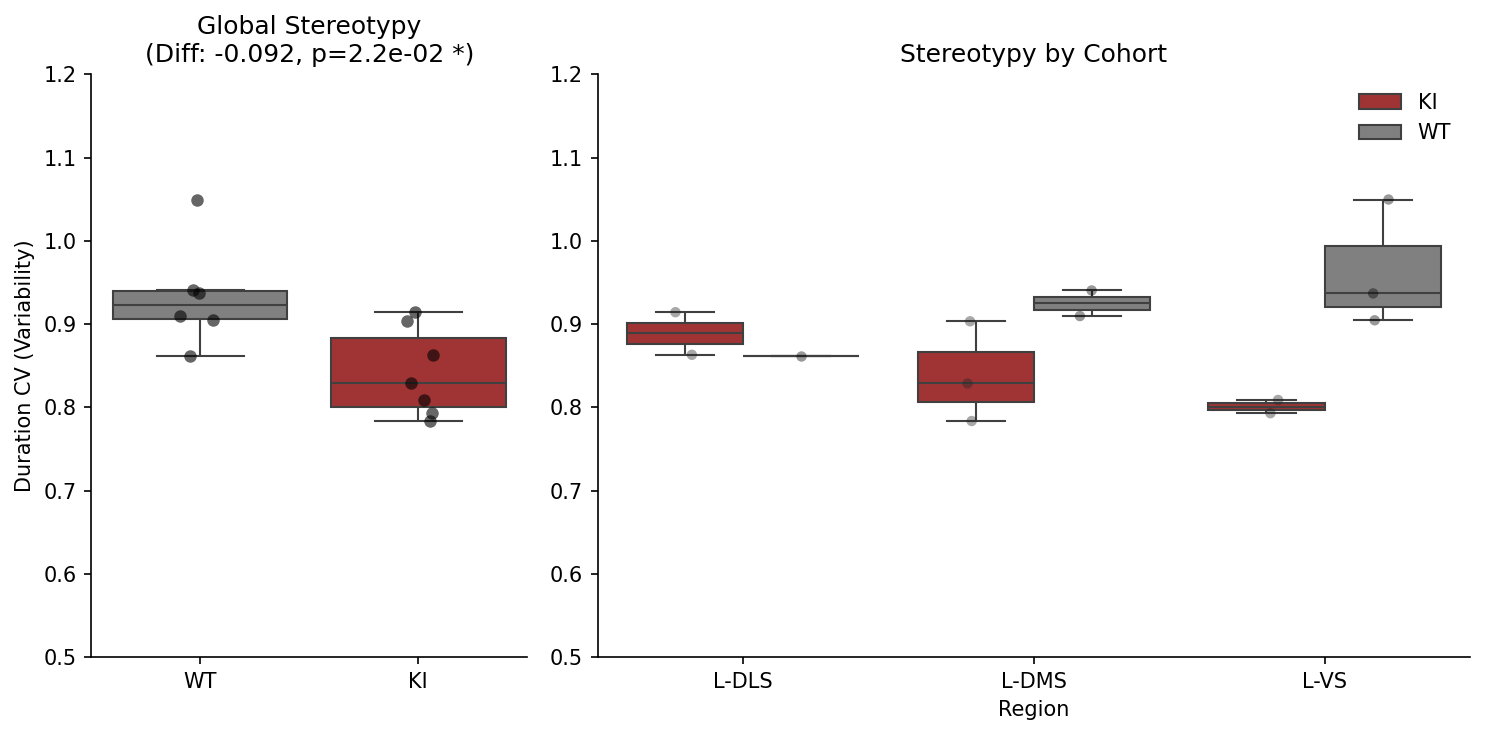


=== BEHAVIORAL STEREOTYPY (Duration CV) ===
Group      | N_Mice | WT Mean  | KI Mean  | Diff     | p-value
----------------------------------------------------------------------
POOLED     | 13     | 0.934    | 0.842    | -0.092   | 2.2e-02 *
L-DMS      | 5      | 0.925    | 0.839    | -0.086   | 2.0e-01 
L-VS       | 5      | 0.964    | 0.801    | -0.163   | 2.0e-01 


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# 1. CONFIGURATION
# ==========================================
MIN_TRIALS_PER_SYLLABLE = 50 
IGNORE_GENOTYPES = {"UNK", None, "nan"}
TARGET_ORIG_LETTER = "G" # Used to identify the 'primary' region of the recording

# ==========================================
# 2. PREP: ATTACH REGION INFO
# ==========================================
if 'long_df' not in globals():
    raise RuntimeError("Kinematics dataframe (long_df) not found. Run the Aggregation cell first.")

# Create a map: session_id -> Brain Region
# We infer the region from the metadata of the sessions list
session_to_region = {}

print("Mapping Sessions to Brain Regions...")
for s in sessions:
    # Look for the Green signal to define the region
    sig_meta = s.metadata.get("signal_meta", {})
    reg = "UNK"
    for info in sig_meta.values():
        if info.get("orig_letter") == TARGET_ORIG_LETTER:
            reg = info.get("brain_reg", "UNK")
            break
    session_to_region[s.session_id] = reg

# Add 'Region' column to long_df if it's missing
if "Region" not in long_df.columns:
    long_df["Region"] = long_df["session_id"].map(session_to_region)
    print(f"Added 'Region' column to long_df.")

# ==========================================
# 3. AGGREGATION (Per Animal)
# ==========================================
# Filter for robust syllables
valid_sylls = long_df[long_df["count"] >= MIN_TRIALS_PER_SYLLABLE].copy()
valid_sylls = valid_sylls[~valid_sylls["genotype"].isin(IGNORE_GENOTYPES)]

# Drop sessions with unknown regions
valid_sylls = valid_sylls[valid_sylls["Region"] != "UNK"]

# Aggregate to ANIMAL level ( Mean of all their syllables)
# Now grouping by ["animal_id", "genotype", "Region"] works!
animal_stereotypy = valid_sylls.groupby(["animal_id", "genotype", "Region"])["duration_cv"].mean().reset_index()

print(f"Analyzed {len(animal_stereotypy)} unique animals.")

# ==========================================
# 4. PLOTTING & STATS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=150, width_ratios=[1, 2])

# --- PLOT A: POOLED (Global Phenotype) ---
ax_pool = axes[0]
sns.boxplot(data=animal_stereotypy, x="genotype", y="duration_cv", 
            palette={"WT": "grey", "KI": "firebrick"}, order=["WT", "KI"], showfliers=False, ax=ax_pool)
sns.stripplot(data=animal_stereotypy, x="genotype", y="duration_cv", 
              color="black", alpha=0.6, size=6, order=["WT", "KI"], ax=ax_pool)

# Stats (Mann-Whitney)
wt_vals = animal_stereotypy[animal_stereotypy["genotype"]=="WT"]["duration_cv"]
ki_vals = animal_stereotypy[animal_stereotypy["genotype"]=="KI"]["duration_cv"]

if len(wt_vals) > 0 and len(ki_vals) > 0:
    u, p_pool = stats.mannwhitneyu(wt_vals, ki_vals)
    diff = ki_vals.mean() - wt_vals.mean()
    sig_str = "***" if p_pool < 0.001 else ("**" if p_pool < 0.01 else ("*" if p_pool < 0.05 else "ns"))
    title_str = f"Global Stereotypy\n(Diff: {diff:+.3f}, p={p_pool:.1e} {sig_str})"
else:
    title_str = "Global Stereotypy (Not enough data)"

ax_pool.set_title(title_str)
ax_pool.set_ylabel("Duration CV (Variability)")
ax_pool.set_xlabel("")
ax_pool.set_ylim(0.5, 1.2)

# --- PLOT B: SPLIT BY REGION (Cohort Check) ---
ax_split = axes[1]
sns.boxplot(data=animal_stereotypy, x="Region", y="duration_cv", hue="genotype",
            palette={"WT": "grey", "KI": "firebrick"}, showfliers=False, ax=ax_split)
sns.stripplot(data=animal_stereotypy, x="Region", y="duration_cv", hue="genotype",
              dodge=True, color="black", alpha=0.4, legend=False, ax=ax_split)

ax_split.set_title("Stereotypy by Cohort")
ax_split.set_ylabel("")
ax_split.legend(loc='upper right', frameon=False)
ax_split.set_ylim(0.5, 1.2)

sns.despine()
plt.tight_layout()
plt.show()

# --- TABLE ---
print("\n=== BEHAVIORAL STEREOTYPY (Duration CV) ===")
print(f"{'Group':<10} | {'N_Mice':<6} | {'WT Mean':<8} | {'KI Mean':<8} | {'Diff':<8} | {'p-value'}")
print("-" * 70)

if len(wt_vals) > 0 and len(ki_vals) > 0:
    print(f"{'POOLED':<10} | {len(animal_stereotypy):<6} | {wt_vals.mean():<8.3f} | {ki_vals.mean():<8.3f} | {diff:<+8.3f} | {p_pool:.1e} {sig_str}")

for reg in sorted(animal_stereotypy["Region"].unique()):
    subset = animal_stereotypy[animal_stereotypy["Region"] == reg]
    wt = subset[subset["genotype"]=="WT"]["duration_cv"]
    ki = subset[subset["genotype"]=="KI"]["duration_cv"]
    
    if len(wt) > 1 and len(ki) > 1:
        u, p = stats.mannwhitneyu(wt, ki)
        d = ki.mean() - wt.mean()
        sig = "*" if p < 0.05 else ""
        print(f"{reg:<10} | {len(subset):<6} | {wt.mean():<8.3f} | {ki.mean():<8.3f} | {d:<+8.3f} | {p:.1e} {sig}")

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, signal
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
BASELINE_WIN = (-2.0, -0.1) # Pre-movement window
ACTIVITY_THRESH_Z = 1.0     # "Active" threshold

MIN_TRIALS = 50
USE_ROBUST_Z = True
TARGET_ORIG_LETTER = "G"
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# ==========================================
# 2. HELPER
# ==========================================
def apply_bessel_filter(series, fs):
    nyquist = fs / 2.0
    if nyquist <= 1.0: return series
    sos = signal.bessel(1, 1.0 / nyquist, btype="high", output="sos")
    valid_mask = ~np.isnan(series)
    res = np.full_like(series, np.nan)
    if valid_mask.sum() > 10:
        res[valid_mask] = signal.sosfiltfilt(sos, series[valid_mask])
    return res

# ==========================================
# 3. AGGREGATION (Syllable-Specific Baseline)
# ==========================================
baseline_data = []
print(f"Calculating Local Burst Occupancy (Pre-Movement)...")

for session in sessions:
    meta = session.metadata
    geno = meta.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    if "SystemTimestamp" in df.columns:
        dt = np.median(np.diff(df["SystemTimestamp"]))
        fs = 1 / dt
    else: fs = 30.0
    
    base_start = int(BASELINE_WIN[0] * fs)
    base_end = int(BASELINE_WIN[1] * fs)
    
    onsets = df["onset"].fillna(0).astype(bool).to_numpy() if "onset" in df.columns else (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    syllable_array = df["syllable"].to_numpy()
    
    sig_meta = meta.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        if info.get("orig_letter") != TARGET_ORIG_LETTER: continue
        region = info.get("brain_reg", "UNK")
        if region in IGNORE_REGIONS: continue
            
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        if col_name is None: continue

        raw_sig = df[col_name].to_numpy()
        filtered_sig = apply_bessel_filter(raw_sig, fs)
        
        if USE_ROBUST_Z and "dff" in col_name:
            sess_med = np.nanmedian(filtered_sig)
            sess_mad = np.nanmedian(np.abs(filtered_sig - sess_med)) * 1.4826
            if sess_mad == 0: sess_mad = 1.0
            z_trace = (filtered_sig - sess_med) / sess_mad
        else:
            z_trace = filtered_sig
            
        max_idx = len(z_trace)
        sess_occupancy = defaultdict(list)
        
        for idx in onset_indices:
            s = idx + base_start
            e = idx + base_end
            if s < 0 or e >= max_idx: continue
            
            segment = z_trace[s:e]
            occupancy = np.mean(segment > ACTIVITY_THRESH_Z)
            sess_occupancy[syllable_array[idx]].append(occupancy)
            
        for syll, occ_vals in sess_occupancy.items():
            if len(occ_vals) >= MIN_TRIALS:
                baseline_data.append({
                    "session_id": session.session_id,
                    "syllable": syll,
                    "Region": region,
                    "Baseline_Occupancy": np.mean(occ_vals)
                })

# ==========================================
# 3. MERGE & LOOP (Dynamic Regions per Hemi)
# ==========================================
if 'long_df' in globals() and not df_da.empty:
    merged_df = pd.merge(df_da, long_df, on=["session_id", "syllable"], how="inner")
    
    if merged_df.empty:
        print("⚠️ Merge resulted in empty dataframe.")
    else:
        unique_hemis = sorted([h for h in merged_df["Hemisphere"].unique() if h not in IGNORE_HEMIS])

        # --- MAIN LOOP OVER FEATURES ---
        for kin_col, kin_name in KINEMATIC_FEATURES:
            
            # --- LOOP OVER HEMISPHERES ---
            for hemi in unique_hemis:
                
                # 1. Filter Data for this Hemisphere FIRST
                hemi_df = merged_df[merged_df["Hemisphere"] == hemi]
                if hemi_df.empty: continue
                
                # 2. DYNAMIC REGIONS: Only get regions that exist in this hemisphere
                current_regions = sorted(hemi_df["Region"].unique())
                if not current_regions: continue

                # 3. Aggregate
                plot_df = hemi_df.groupby(["Region", "genotype", "syllable"]).agg({
                    DOPAMINE_METRIC: "mean",
                    kin_col: "mean",
                    "count": "sum"
                }).reset_index()
                
                plot_df = plot_df[plot_df["count"] >= 100]
                
                if plot_df.empty:
                    print(f"Skipping {hemi} (Not enough data after grouping)")
                    continue
                
                print(f"\n{'='*60}")
                print(f"ANALYSIS: {kin_name.upper()} vs. VALENCE | Hemisphere: {hemi}")
                print(f"{'='*60}")
                
                # --- A. PLOTTING (Dynamic Size) ---
                # Use len(current_regions) instead of global list
                n_cols = len(current_regions)
                fig, axes = plt.subplots(1, n_cols, figsize=(5*n_cols, 5), dpi=150)
                
                # Handle single subplot case
                if n_cols == 1: axes = [axes]
                
                stats_summary = defaultdict(dict) 

                # Iterate only over relevant regions
                for ax, region in zip(axes, current_regions):
                    subset = plot_df[plot_df["Region"] == region]
                    
                    if subset.empty:
                        ax.text(0.5, 0.5, "No Data", ha='center'); continue
                    
                    sns.scatterplot(data=subset, x=kin_col, y=DOPAMINE_METRIC, 
                                    hue="genotype", palette={"WT": "grey", "KI": "firebrick"}, 
                                    style="genotype", s=80, alpha=0.7, ax=ax)
                    
                    ax.axhline(0, color="black", linestyle="--", alpha=0.3) 
                    
                    for geno, color in zip(["WT", "KI"], ["grey", "firebrick"]):
                        g_data = subset[subset["genotype"] == geno]
                        if len(g_data) > 5:
                            r, p = stats.pearsonr(g_data[kin_col], g_data[DOPAMINE_METRIC])
                            slope, intercept, r_val, p_val, stderr = stats.linregress(g_data[kin_col], g_data[DOPAMINE_METRIC])
                            
                            stats_summary[region][geno] = {
                                'r': r, 'p': p, 'slope': slope, 'stderr': stderr, 'n': len(g_data)
                            }

                            sns.regplot(data=g_data, x=kin_col, y=DOPAMINE_METRIC,
                                        scatter=False, color=color, ax=ax, truncate=False)
                            
                            sig_star = "*" if p < 0.05 else ""
                            ax.text(0.05, 0.9 if geno=="WT" else 0.85, 
                                    f"{geno}: r={r:.2f}{sig_star}", transform=ax.transAxes, 
                                    color=color, fontweight='bold', fontsize=9)

                    # Title uses specific region name (e.g. L-DLS)
                    ax.set_title(f"{region} ({kin_name})")
                    ax.set_xlabel(f"{kin_name}")
                    ax.set_ylabel("Peak Valence (Z)")
                    sns.despine(ax=ax)

                plt.tight_layout()
                plt.show()
                
                # --- B. TABLE 1 ---
                print(f"\nTable 1: {kin_name} Coupling ({hemi}-Hemi)")
                print(f"{'Region':<8} | {'Geno':<4} | {'N':<4} | {'Slope':<8} | {'Corr (r)':<10} | {'p-value':<10}")
                print("-" * 65)
                for region in current_regions:
                    for geno in ["WT", "KI"]:
                        if geno in stats_summary[region]:
                            s = stats_summary[region][geno]
                            sig = "***" if s['p'] < 0.001 else ("**" if s['p'] < 0.01 else ("*" if s['p'] < 0.05 else ""))
                            print(f"{region:<8} | {geno:<4} | {s['n']:<4} | {s['slope']:<+8.3f} | {s['r']:<10.3f} | {s['p']:.1e} {sig}")
                
                # --- C. TABLE 2 ---
                print(f"\nTable 2: Genotype Comparison ({hemi}-Hemi)")
                print(f"{'Region':<8} | {'WT Slope':<10} | {'KI Slope':<10} | {'Diff p-val':<10} | {'Result'}")
                print("-" * 65)
                
                for region in current_regions:
                    if "WT" in stats_summary[region] and "KI" in stats_summary[region]:
                        wt = stats_summary[region]["WT"]
                        ki = stats_summary[region]["KI"]
                        
                        slope_diff = wt['slope'] - ki['slope']
                        pooled_se = np.sqrt(wt['stderr']**2 + ki['stderr']**2)
                        z_score = slope_diff / pooled_se
                        p_compare = 2 * (1 - stats.norm.cdf(abs(z_score)))
                        
                        sig = "***" if p_compare < 0.001 else ("**" if p_compare < 0.01 else ("*" if p_compare < 0.05 else "ns"))
                        interp = "DIFFERENT MAP" if p_compare < 0.05 else "SAME MAP"
                            
                        print(f"{region:<8} | {wt['slope']:<10.4f} | {ki['slope']:<10.4f} | {p_compare:.1e} {sig:<3} | {interp}")
                print("\n")

else:
    print("Kinematics dataframe (long_df) not found or dopamine data empty.")

Calculating Local Burst Occupancy (Pre-Movement)...


ValueError: cannot convert float NaN to integer

### Test 5

Aggregating Dopamine (Method: Peak of Mean Trace)...
✅ Generated 706 aggregated syllable responses.
Analyzed 706 locomotor syllable types.

=== PART A: PATH GEOMETRY (Tortuosity) ===


/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.p

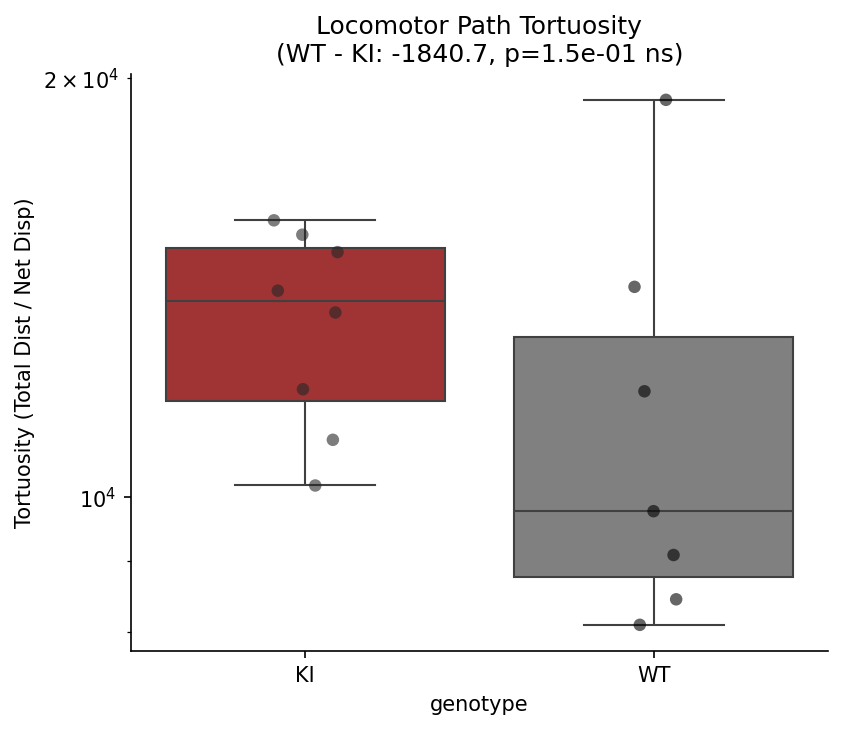


=== PART B: MECHANISM (Does Dopamine Predict Straightness?) ===


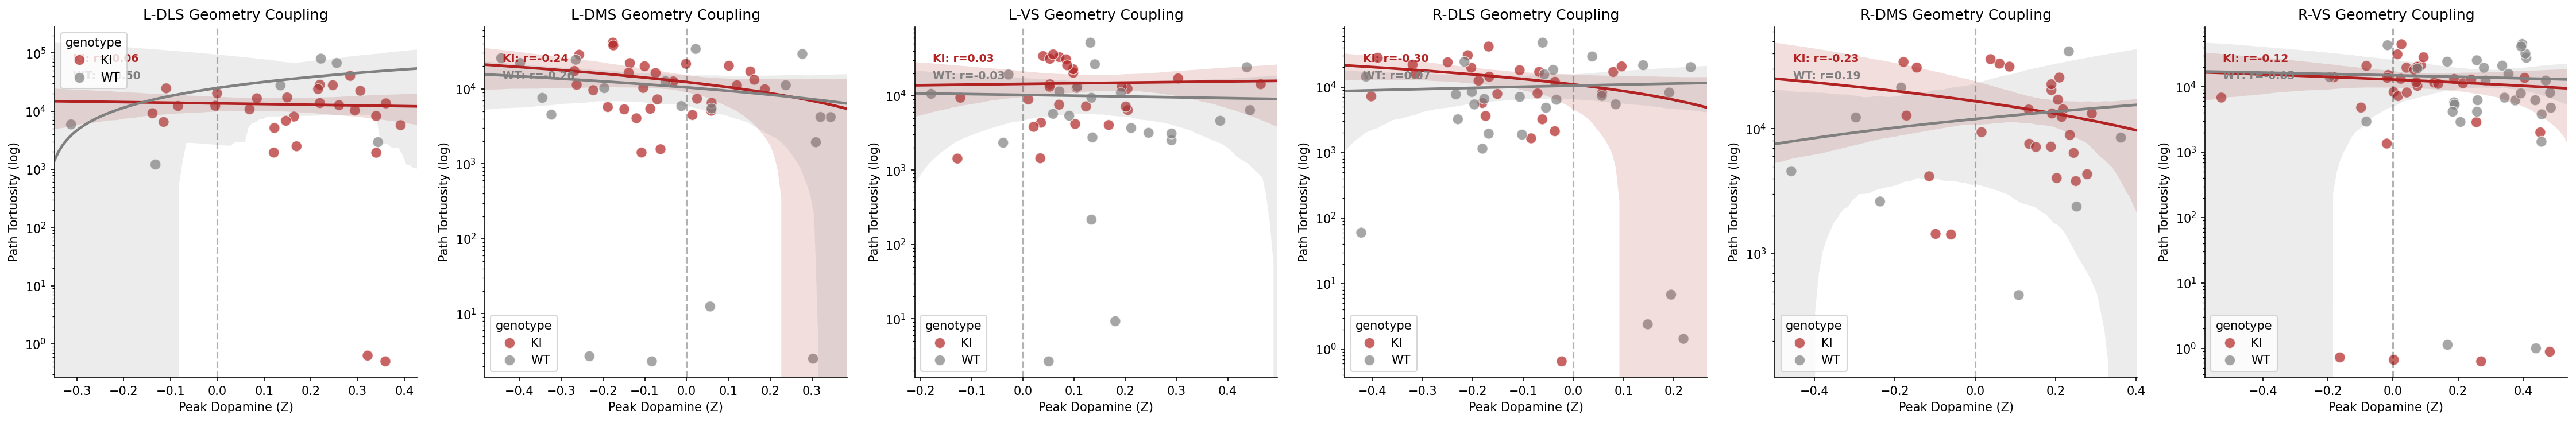


Table: Valence vs. Geometry Correlation
Region   | Geno | N    | Corr (r)   | p-value   
-------------------------------------------------------
L-DLS    | KI   | 28   | -0.057     | 7.7e-01 
L-DLS    | WT   | 6    | 0.497      | 3.2e-01 
L-DMS    | KI   | 29   | -0.238     | 2.1e-01 
L-DMS    | WT   | 19   | -0.260     | 2.8e-01 
L-VS     | KI   | 27   | 0.031      | 8.8e-01 
L-VS     | WT   | 22   | -0.031     | 8.9e-01 
R-DLS    | KI   | 24   | -0.301     | 1.5e-01 
R-DLS    | WT   | 26   | 0.066      | 7.5e-01 
R-DMS    | KI   | 27   | -0.233     | 2.4e-01 
R-DMS    | WT   | 8    | 0.193      | 6.5e-01 
R-VS     | KI   | 32   | -0.124     | 5.0e-01 
R-VS     | WT   | 31   | -0.049     | 7.9e-01 


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, signal
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# Filter: Only analyze "Locomotor" syllables (>10 px/s)
# Tortuosity is unstable/infinite for stationary behaviors
MIN_VELOCITY_THRESH = 10.0 

# Analysis
DOPAMINE_METRIC = 'Peak Z'
WINDOW_SECONDS = 0.3
MIN_TRIALS = 50
USE_ROBUST_Z = True

TARGET_ORIG_LETTER = "G"
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# ==========================================
# 2. PREPARE DOPAMINE (Peak of Average Trace)
# ==========================================
def get_peak_of_average(traces_list, window_idx):
    """
    1. Average all trials into one smooth trace.
    2. Find the max absolute deviation in that smooth trace.
    """
    if not traces_list: return np.nan
    
    # 1. Compute Mean Trace (High SNR)
    stack = np.array(traces_list)
    mean_trace = np.nanmean(stack, axis=0)
    
    # 2. Extract Peak from the Smooth Trace
    # We restrict the peak search to the window of interest
    segment = mean_trace[window_idx]
    
    # Signed Peak (Value at the point of max absolute deviation)
    idx_max = np.argmax(np.abs(segment))
    return segment[idx_max]

dopamine_rows = []
print(f"Aggregating Dopamine (Method: Peak of Mean Trace)...")

for session in sessions:
    meta = session.metadata
    geno = meta.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate Calculation
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0
    
    window_frames = int(WINDOW_SECONDS * fs)
    
    onsets = df["onset"].fillna(0).astype(bool).to_numpy() if "onset" in df.columns else (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    if len(onset_indices) == 0: continue
    syllable_array = df["syllable"].to_numpy()
    
    # Iterate Signals
    sig_meta = meta.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # --- Metadata Logic ---
        color = str(info.get("orig_letter", "UNK")).upper().strip()
        if color == "UNK" and "fiber_num" in info:
             color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
        
        if color != TARGET_ORIG_LETTER: continue
        
        region = str(info.get("brain_reg", "UNK")).strip()
        hemi = str(info.get("hemisphere", "UNK")).strip().replace("Left", "L").replace("Right", "R")
        
        if region in IGNORE_REGIONS or hemi in IGNORE_HEMIS: continue
            
        # Get Data
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        if col_name is None: continue

        signal_data = df[col_name].to_numpy()
        
        # Robust Z-Score Baseline (Session Level)
        if USE_ROBUST_Z and "dff" in col_name:
            sess_med = np.nanmedian(signal_data)
            sess_mad = np.nanmedian(np.abs(signal_data - sess_med)) * 1.4826
            if sess_mad == 0: sess_mad = 1.0
            signal_data = (signal_data - sess_med) / sess_mad

        # --- COLLECT TRACES ---
        # Instead of getting peaks immediately, we store the snippets
        sess_traces = defaultdict(list)
        max_idx = len(signal_data)
        
        for idx in onset_indices:
            if idx + window_frames >= max_idx: continue
            
            # Grab the raw snippet
            segment = signal_data[idx : idx + window_frames]
            
            # Store it
            sess_traces[syllable_array[idx]].append(segment)
            
        # --- AVERAGE & PEAK ---
        # Now we process each syllable group
        for syll, traces in sess_traces.items():
            if len(traces) >= MIN_TRIALS: 
                # Identify the window indices (relative to the slice)
                # Here we just look at the whole slice we grabbed
                win_idx = slice(0, window_frames)
                
                metric = get_peak_of_average(traces, win_idx)
                
                dopamine_rows.append({
                    "session_id": session.session_id,
                    "syllable": syll,
                    "Region": region,
                    "Hemisphere": hemi,
                    DOPAMINE_METRIC: metric
                })

# Create DataFrame
if not dopamine_rows:
    print("⚠️ WARNING: No data found. Check filters.")
    df_da = pd.DataFrame(columns=["session_id", "syllable", "Region", "Hemisphere", DOPAMINE_METRIC])
else:
    df_da = pd.DataFrame(dopamine_rows)
    print(f"✅ Generated {len(df_da)} aggregated syllable responses.")

# ==========================================
# 3. MERGE & FILTER (Robust)
# ==========================================
if 'long_df' in globals():
    
    # --- FIX: SMART MERGE ---
    # If 'Region' exists in both, include it in 'on' keys to prevent duplicates
    merge_cols = ["session_id", "syllable"]
    if "Region" in long_df.columns:
        merge_cols.append("Region")
        
    merged_df = pd.merge(df_da, long_df, on=merge_cols, how="inner")
    
    # Filter for Locomotion
    loco_df = merged_df[merged_df['velocity_p95_median'] > MIN_VELOCITY_THRESH].copy()
    print(f"Analyzed {len(loco_df)} locomotor syllable types.")
    
    # Aggregate
    plot_df = loco_df.groupby(["Region", "genotype", "syllable"]).agg({
        DOPAMINE_METRIC: "mean",
        "tortuosity_avg": "mean",
        "velocity_p95_median": "mean",
        "count": "sum"
    }).reset_index()
    
    plot_df = plot_df[plot_df["count"] >= 100]

    # ==========================================
    # 4. PART A: BEHAVIOR (Do KI mice meander?)
    # ==========================================
    print(f"\n=== PART A: PATH GEOMETRY (Tortuosity) ===")
    
    plt.figure(figsize=(6, 5), dpi=150)
    
    # Aggregate to Animal Level
    animal_geo = loco_df.groupby(["animal_id", "genotype"])["tortuosity_avg"].mean().reset_index()
    
    # Dynamic Order (Fixes empty plot if labels differ)
    my_order = sorted(animal_geo["genotype"].unique())
    my_pal = {g: "firebrick" if "KI" in g else "grey" for g in my_order}
    
    # Boxplot (Fixed Warnings: added hue, legend=False)
    sns.boxplot(data=animal_geo, x="genotype", y="tortuosity_avg", hue="genotype",
                palette=my_pal, order=my_order, showfliers=False, legend=False)
    
    # Strip Plot
    sns.stripplot(data=animal_geo, x="genotype", y="tortuosity_avg", hue="genotype",
                  color="black", alpha=0.6, size=6, order=my_order, legend=False)
    
    # Statistics
    if len(my_order) == 2:
        g1 = animal_geo[animal_geo["genotype"]==my_order[0]]["tortuosity_avg"]
        g2 = animal_geo[animal_geo["genotype"]==my_order[1]]["tortuosity_avg"]
        u, p_beh = stats.mannwhitneyu(g1, g2)
        diff = g2.mean() - g1.mean()
        sig_str = "***" if p_beh < 0.001 else ("**" if p_beh < 0.01 else ("*" if p_beh < 0.05 else "ns"))
        plt.title(f"Locomotor Path Tortuosity\n({my_order[1]} - {my_order[0]}: {diff:+.1f}, p={p_beh:.1e} {sig_str})")
    else:
        plt.title("Locomotor Path Tortuosity")

    plt.ylabel("Tortuosity (Total Dist / Net Disp)")
    
    # FIX: Your values are huge (15,000+), so we cannot use ylim(1,3)
    # We use log scale or autoscaling instead
    # plt.ylim(1.0, 3.0) <--- Removed this restriction
    plt.yscale('log') # Log scale handles the massive range better
    
    sns.despine()
    plt.show()

    # ==========================================
    # 5. PART B: MECHANISM (Correlation)
    # ==========================================
    print(f"\n=== PART B: MECHANISM (Does Dopamine Predict Straightness?) ===")
    
    unique_regions = sorted(plot_df["Region"].unique())
    n_cols = len(unique_regions)
    if n_cols == 0:
        print("No regions found for correlation analysis.")
    else:
        fig, axes = plt.subplots(1, n_cols, figsize=(5*n_cols, 5), dpi=150)
        if n_cols == 1: axes = [axes]
        
        stats_table = []

        for ax, region in zip(axes, unique_regions):
            subset = plot_df[plot_df["Region"] == region]
            
            # Scatter with Hue
            sns.scatterplot(data=subset, x=DOPAMINE_METRIC, y="tortuosity_avg", 
                            hue="genotype", palette=my_pal, 
                            s=80, alpha=0.7, ax=ax)
            
            ax.axvline(0, color="black", linestyle="--", alpha=0.3)
            
            for geno in my_order:
                color = my_pal.get(geno, "black")
                g_data = subset[subset["genotype"] == geno]
                
                if len(g_data) > 5:
                    sns.regplot(data=g_data, x=DOPAMINE_METRIC, y="tortuosity_avg",
                                scatter=False, color=color, ax=ax, truncate=False)
                    
                    r, p = stats.pearsonr(g_data[DOPAMINE_METRIC], g_data["tortuosity_avg"])
                    stats_table.append({"Region": region, "Geno": geno, "N": len(g_data), "R": r, "P": p})
                    
                    # Annotate (smart positioning)
                    y_pos = 0.9 if geno == my_order[0] else 0.85
                    ax.text(0.05, y_pos, f"{geno}: r={r:.2f}", transform=ax.transAxes, 
                            color=color, fontweight='bold', fontsize=9)
            
            ax.set_title(f"{region} Geometry Coupling")
            ax.set_xlabel("Peak Dopamine (Z)")
            ax.set_ylabel("Path Tortuosity (log)")
            ax.set_yscale('log') # Match the boxplot scale
            sns.despine(ax=ax)

        plt.tight_layout()
        plt.show()
        
        # Table
        if stats_table:
            print(f"\nTable: Valence vs. Geometry Correlation")
            print(f"{'Region':<8} | {'Geno':<4} | {'N':<4} | {'Corr (r)':<10} | {'p-value':<10}")
            print("-" * 55)
            for row in stats_table:
                sig = "***" if row['P'] < 0.001 else ("**" if row['P'] < 0.01 else ("*" if row['P'] < 0.05 else ""))
                print(f"{row['Region']:<8} | {row['Geno']:<4} | {row['N']:<4} | {row['R']:<10.3f} | {row['P']:.1e} {sig}")

else:
    print("Kinematics dataframe (long_df) not found.")

### Test 6

Analyzed 15 unique animals.


/tmp/ipykernel_336765/3081045994.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=animal_stats, x="genotype", y=col, order=["WT", "KI"],
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping wi

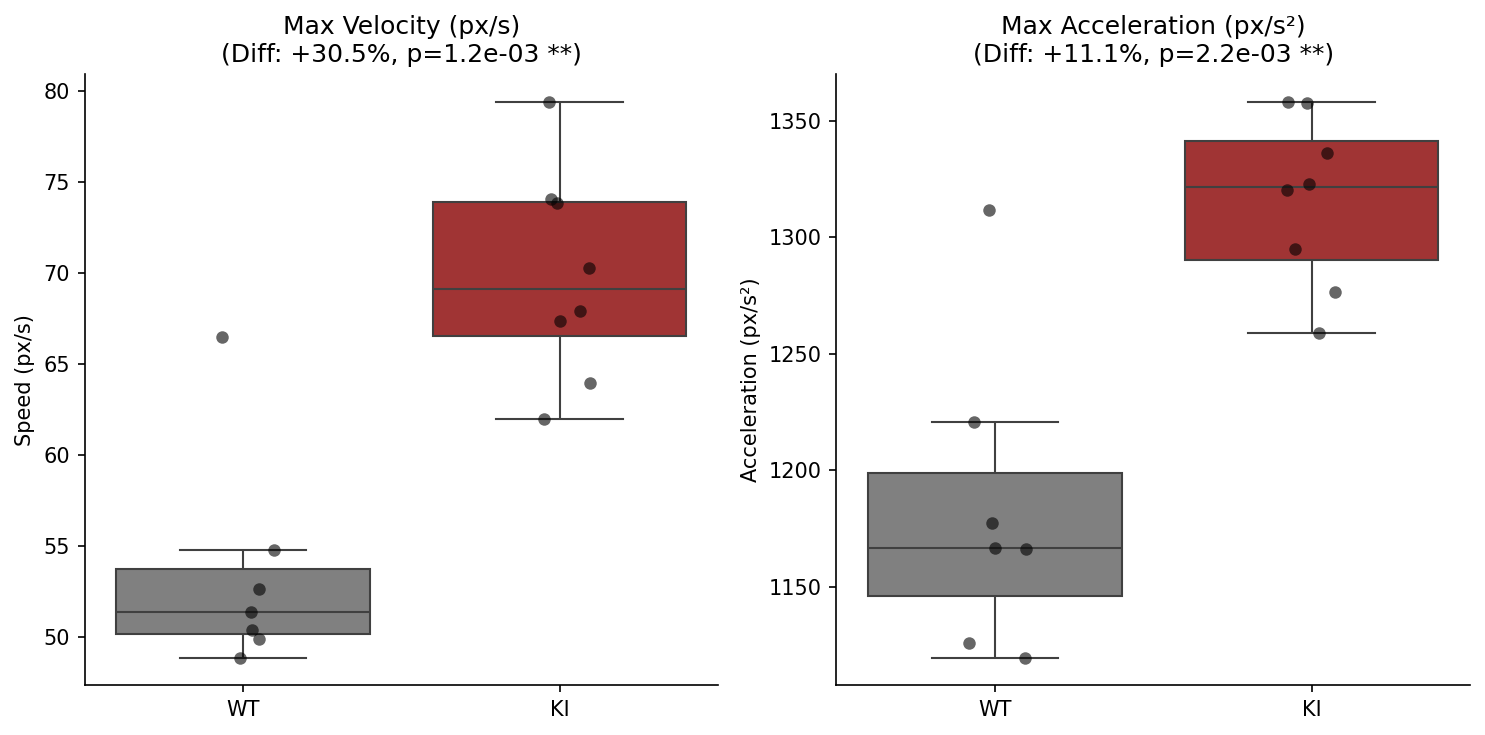


=== HYPERACTIVITY PHENOTYPE (Global) ===
Metric                    | WT Mean    | KI Mean    | % Change   | p-value
---------------------------------------------------------------------------
Max Velocity (px/s)       | 53.51      | 69.86      | +30.5    % | 1.2e-03 *
Max Acceleration (px/s²)  | 1183.99    | 1315.61    | +11.1    % | 2.2e-03 *


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# 1. CONFIGURATION
# ==========================================
METRICS = [
    ('velocity_p95_median', 'Max Velocity (px/s)'),
    ('accel_p95_median', 'Max Acceleration (px/s²)')
]

MIN_TRIALS = 100 
IGNORE_GENOTYPES = {"UNK", None, "nan"}

# ==========================================
# 2. AGGREGATION (Per Animal)
# ==========================================
if 'long_df' not in globals():
    raise RuntimeError("Kinematics dataframe (long_df) not found. Run the Aggregation cell first.")

# Filter for robust data
clean_df = long_df[long_df["count"] >= MIN_TRIALS].copy()
clean_df = clean_df[~clean_df["genotype"].isin(IGNORE_GENOTYPES)]

# Aggregate to ANIMAL level (Global Phenotype)
# We pool across all regions because "Hyperactivity" is a whole-body trait
animal_stats = clean_df.groupby(["animal_id", "genotype"]).agg({
    'velocity_p95_median': 'mean',
    'accel_p95_median': 'mean'
}).reset_index()

print(f"Analyzed {len(animal_stats)} unique animals.")

# ==========================================
# 3. PLOTTING & STATS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=150)

for i, (col, label) in enumerate(METRICS):
    ax = axes[i]
    
    # Plot
    sns.boxplot(data=animal_stats, x="genotype", y=col, order=["WT", "KI"],
                palette={"WT": "grey", "KI": "firebrick"}, showfliers=False, ax=ax)
    sns.stripplot(data=animal_stats, x="genotype", y=col, order=["WT", "KI"],
                  color="black", alpha=0.6, size=6, ax=ax)
    
    # Stats
    wt_vals = animal_stats[animal_stats["genotype"]=="WT"][col]
    ki_vals = animal_stats[animal_stats["genotype"]=="KI"][col]
    
    u, p = stats.mannwhitneyu(wt_vals, ki_vals)
    
    # Calculate % Increase
    mean_diff = ki_vals.mean() - wt_vals.mean()
    pct_change = (mean_diff / wt_vals.mean()) * 100
    sig_str = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    
    ax.set_title(f"{label}\n(Diff: {pct_change:+.1f}%, p={p:.1e} {sig_str})")
    ax.set_xlabel("")
    
    # Add descriptive y-label
    if i == 0: ax.set_ylabel("Speed (px/s)")
    else: ax.set_ylabel("Acceleration (px/s²)")

sns.despine()
plt.tight_layout()
plt.show()

# --- TABLE ---
print("\n=== HYPERACTIVITY PHENOTYPE (Global) ===")
print(f"{'Metric':<25} | {'WT Mean':<10} | {'KI Mean':<10} | {'% Change':<10} | {'p-value'}")
print("-" * 75)

for col, label in METRICS:
    wt = animal_stats[animal_stats["genotype"]=="WT"][col]
    ki = animal_stats[animal_stats["genotype"]=="KI"][col]
    
    u, p = stats.mannwhitneyu(wt, ki)
    pct = ((ki.mean() - wt.mean()) / wt.mean()) * 100
    sig = "*" if p < 0.05 else ""
    
    print(f"{label:<25} | {wt.mean():<10.2f} | {ki.mean():<10.2f} | {pct:<+9.1f}% | {p:.1e} {sig}")